In [1]:
# Standard library
import os
import subprocess
import shutil
import copy
import random

# Data & image processing
import cv2
import numpy as np
import pandas as pd
from urllib import request
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from skimage.feature import hog

# Visualisation
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# Machine learning
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier as RFC, VotingClassifier
from sklearn.metrics import make_scorer, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.datasets import fetch_lfw_people



In [2]:
# ── Install dependencies not available by default on Kaggle ──────────────────
import importlib, subprocess, sys

def _ensure(package, import_name=None):
    import_name = import_name or package
    if importlib.util.find_spec(import_name) is None:
        print(f"Installing {package}...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package, '-q'])
    else:
        print(f"{package} already available.")

_ensure('deepface')
_ensure('tf-keras', 'tf_keras')

# ── Deep learning imports (after install) ─────────────────────────────────────
from deepface import DeepFace

Installing deepface...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.5/169.5 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.4/208.4 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.9/67.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.3 MB/s eta 0:00:00
tf-keras already available.


2026-04-07 22:01:03.660901: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775599263.908977      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775599263.978335      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775599264.538571      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775599264.538614      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775599264.538616      24 computation_placer.cc:177] computation placer alr

26-04-07 22:01:28 - Directory /root/.deepface has been created
26-04-07 22:01:28 - Directory /root/.deepface/weights has been created


<div style="width:100%; height:140px">
    <img src="https://www.kuleuven.be/internationaal/thinktank/fotos-en-logos/ku-leuven-logo.png/image_preview" width = auto, heigh = 200px align=left>
</div>


KUL H02A5a Computer Vision: Group Assignment 1
---------------------------------------------------------------
<div style="height:50px"></div>


Student names: Natalia Iglesias Bueno (R0877632), Carolina Marugan Rubio (r1072969), Merlijn Pietercil (r0852251), David Vargas Jorba (r1087132) </span>.

The goal of this assignment is to explore more advanced techniques for constructing features that better describe objects of interest and to perform face recognition using these features. This assignment will be delivered in groups of 5 (either composed by you or randomly assigned by your TA's).

---------------------------------------------------------------
This notebook is structured as follows:

0. Data loading & Preprocessing
1. Feature Representations
2. Evaluation Metrics 
3. Classifiers
4. Experiments
5. Publishing best results
6. Discussion

Make sure that your notebook is **self-contained** and **fully documented**. Provide strong arguments for the design choices that you made and what insights you got from your experiments. Make use of the *Group assignment 1* forum/discussion board on Toledo if you have any questions.

Good luck! 


<div class="alert alert-block alert-info">
<b>NOTE:</b> This notebook is just a example/template, feel free to adjust in any way you please! Just keep things organised and document accordingly!
</div>

<div class="alert alert-block alert-info">
<b>NOTE:</b> Clearly indicate the improvements that you make!!! You can for instance use titles like: <i>3.1. Improvement: Non-linear SVM with RBF Kernel.<i>
</div>
    
---------------------------------------------------------------
# 0. Data loading & Preprocessing

## 0.1. Loading data
The training set is many times smaller than the test set and this might strike you as odd, however, this is close to a real world scenario where your system might be put through daily use! In this session we will try to do the best we can with the data that we've got! 

In [3]:
# Input data files are available in the read-only "../input/" directory

train = pd.read_csv(
    '/kaggle/input/competitions/kul-computer-vision-ga-1-2026/train_set.csv', index_col = 0)
train.index = train.index.rename('id')

test = pd.read_csv(
    '/kaggle/input/competitions/kul-computer-vision-ga-1-2026/test_set.csv', index_col = 0)
test.index = test.index.rename('id')

# read the images as numpy arrays and store in "img" column
train['img'] = [cv2.cvtColor(np.load('/kaggle/input/competitions/kul-computer-vision-ga-1-2026/train/train_{}.npy'.format(index), allow_pickle=False), cv2.COLOR_BGR2RGB) 
                for index, row in train.iterrows()]

test['img'] = [cv2.cvtColor(np.load('/kaggle/input/competitions/kul-computer-vision-ga-1-2026/test/test_{}.npy'.format(index), allow_pickle=False), cv2.COLOR_BGR2RGB) 
                for index, row in test.iterrows()]
  

train_size, test_size = len(train),len(test)

"The training set contains {} examples, the test set contains {} examples.".format(train_size, test_size)

'The training set contains 80 examples, the test set contains 1816 examples.'

*Note: this dataset is a subset of the* [*VGG face dataset*](https://www.robots.ox.ac.uk/~vgg/data/vgg_face/).

## 0.2. A first look
Let's have a look at the data columns and class distribution.

In [4]:
# The training set contains an identifier, name, image information and class label
train.head(1)

,name,class,img
id,,,
0,Mila_Kunis,2,"[[[50, 31, 25], [49, 30, 24], [49, 30, 24], [4..."


In [5]:
# The test set only contains an identifier and corresponding image information.

test.head(1)

,img
id,
0,"[[[209, 210, 205], [208, 209, 204], [208, 209,..."


In [6]:
# The class distribution in the training set:
train.groupby('name').agg({'img':'count', 'class': 'max'})

,img,class
name,,
Jesse_Eisenberg,30,1
Michael_Cera,10,0
Mila_Kunis,30,2
Sarah_Hyland,10,0


Note that **Jesse is assigned the classification label 1**, and **Mila is assigned the classification label 2**. The dataset also contains 20 images of **look alikes (assigned classification label 0)**.

# 1. Preprocess data
## 1.1 Face Detection

Before extracting features, all images must be cropped to contain only the face of interest. We implement two face detectors:

- **HAAR cascade (Section 1.1.1)** (baseline): a classical sliding-window detector. Fast but brittle on non-frontal poses and varying lighting.
- **YuNet (Section 1.1.2)** (improved): a lightweight CNN-based detector that handles tilted faces, partial occlusion, and lighting variation more robustly. Used as the primary detector; HAAR is kept as a fallback.

Two confidence thresholds are used: 0.6 for training (stricter, to keep only reliable detections and avoid polluting feature representations with noise) and 0.3 for testing (more lenient, since any spurious detections are passed to the classifier which can rule them out, maximising recall at the detection stage is therefore safe).

Training uses a two-pass strategy for images with multiple detected faces. Pass 1 resolves single-face images and builds a pixel-space centroid per class. Pass 2 selects the face closest (L2 distance) to its class centroid, principled since ground-truth labels are available. If no centroid exists yet, the largest face is taken as fallback. If both YuNet and HAAR fail, the sample is dropped entirely.

Testing returns all detected faces per image for independent classification. This is valid since classes 1 and 2 never co-occur in the same image. If both detectors fail, a NaN placeholder is returned since test samples cannot be dropped.

### 1.1.1 Baseline: HAAR Face Detector

In [7]:
class HAARPreprocessor():
    """Preprocessing pipeline built around HAAR feature based cascade classifiers. """

    def __init__(self, path, face_size):
        self.face_size = face_size
        file_path = os.path.join(path, "haarcascade_frontalface_default.xml")
        if not os.path.exists(file_path):
            if not os.path.exists(path):
                os.makedirs(path)
            self.download_model(file_path)

        self.classifier = cv2.CascadeClassifier(file_path)

    def download_model(self, path):
        url = "https://raw.githubusercontent.com/opencv/opencv/master/data/"\
            "haarcascades/haarcascade_frontalface_default.xml"

        with request.urlopen(url) as r, open(path, 'wb') as f:
            f.write(r.read())

    def detect_faces(self, img):
        """Detect all faces in an image."""

        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        return self.classifier.detectMultiScale(
            img_gray,
            scaleFactor=1.2,
            minNeighbors=5,
            minSize=(30, 30),
            flags=cv2.CASCADE_SCALE_IMAGE
        )

    def extract_faces(self, img):
        """Returns all faces (cropped) in an image."""

        faces = self.detect_faces(img)

        return [img[y:y+h, x:x+w] for (x, y, w, h) in faces]

    def preprocess(self, data_row):
        faces = self.extract_faces(data_row['img'])

        # if no faces were found, return NaN array
        if len(faces) == 0:
            nan_img = np.empty(self.face_size + (3,))
            nan_img[:] = np.nan
            return nan_img

        # only return the first face
        return cv2.resize(faces[0], self.face_size, interpolation=cv2.INTER_AREA)

    def __call__(self, data):
        # Keep float dtype so NaN markers (no face found) are preserved.
        return np.stack([self.preprocess(row) for _, row in data.iterrows()])

In [8]:
def plot_detector_comparison_by_class(train_df, haar_X, yunet_X):
    """
    Visualises preprocessing side by side, grouped by class.
    Layout: all samples as rows x (3 classes * 3 cols) — Original | HAAR | YuNet per class.
    """
    class_names = {0: "Lookalike", 1: "Jesse", 2: "Mila"}
    classes = sorted(train_df["class"].unique())

    # Reset index so positional indexing matches haar_X / yunet_X arrays
    df_pos = train_df.reset_index(drop=True)

    # All positional indices per class
    samples = {
        cls: df_pos[df_pos["class"] == cls].index.tolist()
        for cls in classes
    }

    n_rows = max(len(v) for v in samples.values())
    n_cols = len(classes) * 3

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.3, n_rows * 2.5))
    axes = np.atleast_2d(axes)

    for cls_i, cls in enumerate(classes):
        base_col = cls_i * 3
        cname = class_names.get(cls, f"Class {cls}")

        # Column headers: class name on the middle column
        axes[0, base_col    ].set_title("Original",        fontsize=8)
        axes[0, base_col + 1].set_title(f"{cname}HAAR", fontsize=9, fontweight="bold")
        axes[0, base_col + 2].set_title("YuNet",           fontsize=8)

        for row_i, pos in enumerate(samples[cls]):
            orig_img  = df_pos.loc[pos, "img"]
            haar_img  = haar_X[pos]
            yunet_img = yunet_X[pos]

            for j, img in enumerate([orig_img, haar_img, yunet_img]):
                ax = axes[row_i, base_col + j]
                if img is None or (isinstance(img, np.ndarray) and np.isnan(img).any()):
                    ax.imshow(np.zeros((100, 100, 3), dtype=np.uint8))
                    ax.text(0.5, 0.5, "No face", ha="center", va="center",
                            transform=ax.transAxes, color="white", fontsize=8)
                else:
                    ax.imshow(img.astype(np.uint8))
                ax.axis("off")

        # Hide unused rows for this class column group
        for row_i in range(len(samples[cls]), n_rows):
            for j in range(3):
                axes[row_i, base_col + j].axis("off")

    # Draw vertical separator lines between class groups
    for sep in range(1, len(classes)):
        x = sep * 3 - 0.5
        fig.add_artist(plt.Line2D(
            [x / n_cols, x / n_cols], [0, 1],
            transform=fig.transFigure, color="gray", linewidth=1.5, linestyle="--"
        ))

    plt.suptitle("Detector comparison by class  (Original | HAAR | YuNet)",
                 fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


### 1.1.2 YuNet Face Detector

In [9]:
class AdvancedYuNetPreprocessor():
    """
    Preprocessing pipeline using OpenCV's YuNet deep learning face detector.

    - Training: two-pass approach — single-face images build per-class pixel-space
      centroids; multi-face images select the face closest to their class centroid.
      Falls back to largest face if no centroid is available.
      If both YuNet and HAAR find no face, the sample is dropped from the training set.
    - Testing: all detected faces are returned for independent classification,
      since classes 1 and 2 never co-occur in the same image.
      If both detectors fail, a NaN image is returned (cannot drop test samples).
    - conf_threshold: lowered to 0.6 (from default 0.9) to improve recall.
    - haar_fallback: if YuNet finds no face, fall back to HAAR detection.
    """

    MODEL_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"

    def __init__(self, model_path, face_size=(100, 100),
                 conf_threshold=0.6, test_conf_threshold=0.3, haar_fallback=None):
        self.face_size = face_size
        self.conf_threshold = conf_threshold
        self.test_conf_threshold = test_conf_threshold
        self.haar_fallback = haar_fallback
        self.dropped_train_indices = []  # track dropped samples for reporting

        if not os.path.exists(model_path):
            os.makedirs(os.path.dirname(model_path), exist_ok=True)
            self.download_model(model_path)
        self.detector = cv2.FaceDetectorYN.create(
            model_path, "", (320, 320),
            score_threshold=self.conf_threshold
        )

    def download_model(self, path):
        with request.urlopen(self.MODEL_URL) as r, open(path, 'wb') as f:
            f.write(r.read())

    def detect_faces(self, img):
        """Detect all faces in an image. Returns bounding boxes or empty list."""
        h, w = img.shape[:2]
        self.detector.setInputSize((w, h))
        _, faces = self.detector.detect(img)
        return faces if faces is not None else []

    def _crop_and_resize(self, img, face):
        """Crop a single face detection from img and resize to face_size."""
        x, y, w, h = face[:4].astype(int)
        x, y = max(0, x), max(0, y)
        x2 = min(img.shape[1], x + w)
        y2 = min(img.shape[0], y + h)
        crop = img[y:y2, x:x2]
        if crop.size == 0:
            return None
        return cv2.resize(crop, self.face_size, interpolation=cv2.INTER_AREA)

    def extract_faces(self, img):
        """Returns all detected faces (cropped and resized) from an image."""
        return [
            cropped for face in self.detect_faces(img)
            if (cropped := self._crop_and_resize(img, face)) is not None
        ]

    def extract_faces_with_scores(self, img):
        """Returns (crop, detection_score, bbox) for each detected face.
        bbox = (x, y, w, h) in original image pixel coordinates.
        """
        results = []
        for face in self.detect_faces(img):
            cropped = self._crop_and_resize(img, face)
            if cropped is not None:
                x, y, w, h = face[:4].astype(int)
                results.append((cropped, float(face[14]), (x, y, w, h)))
        return results

    def _nan_img(self):
        nan_img = np.empty(self.face_size + (3,))
        nan_img[:] = np.nan
        return nan_img

    def _haar_face(self, data_row):
        """
        Attempt HAAR fallback for a single row.
        Returns the detected face array, or None if HAAR also fails.
        """
        if self.haar_fallback is None:
            return None
        result = self.haar_fallback.preprocess(data_row)
        # HAARPreprocessor returns a NaN array when no face is found
        if isinstance(result, np.ndarray) and np.isnan(result).any():
            return None
        return result

    def _preprocess_train(self, data):
        """
        Two-pass training preprocessor.
        Pass 1: resolve all single-face images, build per-class pixel-space centroids.
        Pass 2: for multi-face images, select the face closest to the class centroid.
                Falls back to largest face if no centroid is available.
        Samples where both YuNet and HAAR find no face are dropped entirely.
        Returns (X, valid_indices) so the caller can filter train_y accordingly.
        """
        results = {}
        multi_face_buffer = []
        class_face_vectors = {}
        self.dropped_train_indices = []

        # Pass 1: single-face images
        for idx, row in data.iterrows():
            faces = self.extract_faces(row['img'])
            if len(faces) == 0:
                # YuNet failed — try HAAR fallback
                haar_result = self._haar_face(row)
                if haar_result is not None:
                    results[idx] = haar_result
                    cls = row['class']
                    class_face_vectors.setdefault(cls, []).append(
                        haar_result.flatten().astype(np.float64)
                    )
                else:
                    # Both detectors failed — mark for removal
                    self.dropped_train_indices.append(idx)
                    print(f"  [DROP] index={idx}, name={row['name']} — no face detected by either detector.")
            elif len(faces) == 1:
                results[idx] = faces[0]
                cls = row['class']
                class_face_vectors.setdefault(cls, []).append(
                    faces[0].flatten().astype(np.float64)
                )
            else:
                multi_face_buffer.append((idx, row, faces, row['class']))

        # Compute per-class centroids from single-face images
        class_centroids = {
            cls: np.mean(np.stack(vecs), axis=0)
            for cls, vecs in class_face_vectors.items()
        }

        # Pass 2: multi-face images
        for idx, row, faces, cls in multi_face_buffer:
            if cls in class_centroids:
                centroid = class_centroids[cls]
                dists = [
                    np.linalg.norm(f.flatten().astype(np.float64) - centroid)
                    for f in faces
                ]
                results[idx] = faces[int(np.argmin(dists))]
            else:
                largest_idx = int(np.argmax([f.shape[0] * f.shape[1] for f in faces]))
                results[idx] = faces[largest_idx]

        # Only return samples that were successfully processed
        valid_indices = [idx for idx in data.index if idx not in self.dropped_train_indices]
        X = np.stack([results[idx] for idx in valid_indices])
        return X, valid_indices

    def _preprocess_test(self, data):
        """
        Test preprocessor. Returns a list of (crop, score, bbox) tuples per image.
        All detected faces are returned for independent classification.
        Uses a lower confidence threshold than training to maximise recall.
        If both detectors fail, a NaN image is returned (cannot drop test samples).
        """
        self.detector.setScoreThreshold(self.test_conf_threshold)
        all_faces = []
        for _, row in data.iterrows():
            faces = self.extract_faces_with_scores(row['img'])
            if len(faces) > 0:
                all_faces.append(faces)
            else:
                haar_result = self._haar_face(row)
                if haar_result is not None:
                    all_faces.append([(haar_result, 0.0, None)])
                else:
                    # Both failed — return NaN, cannot drop test samples
                    all_faces.append([(self._nan_img(), 0.0, None)])
        self.detector.setScoreThreshold(self.conf_threshold)  # restore
        return all_faces

    def __call__(self, data, mode='train'):
        """
        mode='train': returns (X ndarray of shape (N, H, W, 3), valid_indices list)
                      N may be smaller than len(data) if samples were dropped.
        mode='test':  returns list of length len(data), each element a list of face arrays.
        """
        if mode == 'train':
            return self._preprocess_train(data)
        elif mode == 'test':
            return self._preprocess_test(data)
        else:
            raise ValueError(f"Unknown mode '{mode}'. Use 'train' or 'test'.")



### 1.1.3 Face Detector Comparison

  [DROP] index=65, name=Mila_Kunis — no face detected by either detector.

Dropped 1/80 training samples (no face detected by either detector).
Remaining training samples: 79


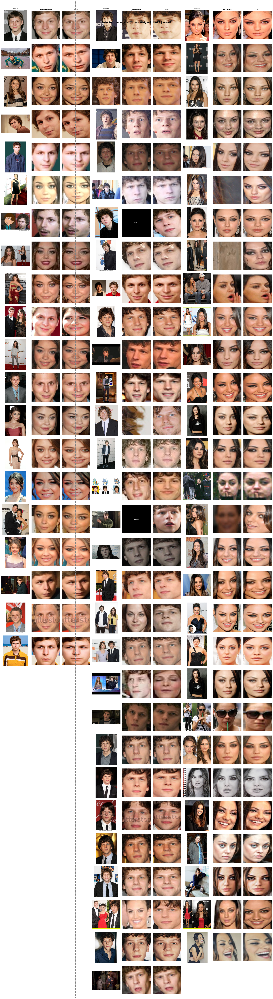

test_X: (2735, 100, 100, 3)  (1816 images, 2735 total faces)
Images with >1 face: 520


In [10]:
FACE_SIZE = (100, 100)
# Instantiate both detectors
haar_preprocessor = HAARPreprocessor(path='models', face_size=FACE_SIZE)
train_X_haar = haar_preprocessor(train)

yunet_preprocessor = AdvancedYuNetPreprocessor(
    model_path='models/face_detection_yunet_2023mar.onnx',
    face_size=FACE_SIZE,
    conf_threshold=0.6,
    test_conf_threshold=0.3,
    haar_fallback=haar_preprocessor
)

# train_X and train_y are now aligned after dropping undetectable samples
train_X, valid_indices = yunet_preprocessor(train, mode='train')
train_filtered = train.loc[valid_indices]
train_y = train_filtered['class'].values

n_dropped = len(yunet_preprocessor.dropped_train_indices)
print(f"\nDropped {n_dropped}/{len(train)} training samples (no face detected by either detector).")
print(f"Remaining training samples: {len(train_X)}")

plot_detector_comparison_by_class(train_filtered, train_X_haar[train.index.isin(valid_indices)], train_X)
# Preprocess test set — keep ALL detected faces per image
# test_face_counts tracks how many faces each image contributed
test_all_faces   = yunet_preprocessor(test, mode='test')
test_face_counts = [len(faces) for faces in test_all_faces]
test_X           = np.stack([face  for faces in test_all_faces for face, _,     _ in faces])
test_face_scores = np.array([score for faces in test_all_faces for _,    score,  _ in faces])
test_face_bboxes = [bbox              for faces in test_all_faces for _,    _,  bbox in faces]

# For each face in test_X, record which original image it came from
test_image_idx = np.repeat(np.arange(len(test_face_counts)), test_face_counts)

print(f"test_X: {test_X.shape}  ({len(test_face_counts)} images, {sum(test_face_counts)} total faces)")
print(f"Images with >1 face: {sum(1 for c in test_face_counts if c > 1)}")


### 1.1.4 Discussion Results: Face Detection

YuNet consistently draws tighter bounding boxes, cropping out more background and producing cleaner inputs, directly benefiting downstream feature extraction. It also handles tilted and non-frontal faces noticeably better than HAAR, which tends to miss or poorly crop such cases entirely.

The centroid-based multi-face selection occasionally picks the wrong face, but this is a minor issue. It could be further improved by applying the classification pipeline to ambiguous multi-face training images , similar to how the test pipeline handles them, rather than relying solely on pixel-space centroids.

Samples where both detectors fail are dropped, these correspond to corrupt or unusable images where no face region can be reliably identified.

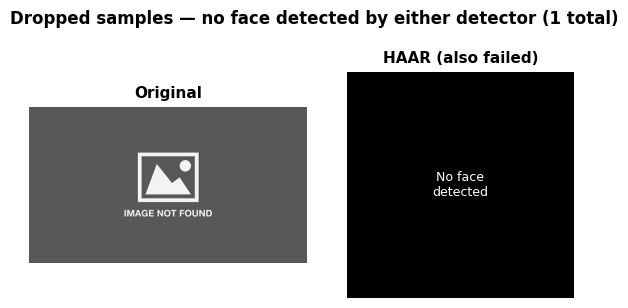

In [11]:
# Show images where no face was detected by either detector
if n_dropped > 0:
    dropped_df = train.loc[yunet_preprocessor.dropped_train_indices]
    dropped_haar = train_X_haar[train.index.isin(yunet_preprocessor.dropped_train_indices)]

    n = len(dropped_df)
    fig, axes = plt.subplots(n, 2, figsize=(6, 3 * n))
    axes = np.atleast_2d(axes)

    axes[0, 0].set_title('Original', fontsize=11, fontweight='bold')
    axes[0, 1].set_title('HAAR (also failed)', fontsize=11, fontweight='bold')

    def _safe_show_dropped(ax, img):
        if img is None or (isinstance(img, np.ndarray) and np.isnan(img).all()):
            ax.imshow(np.zeros((*FACE_SIZE, 3), dtype=np.uint8))
            ax.text(0.5, 0.5, 'No face\ndetected',
                    ha='center', va='center', transform=ax.transAxes,
                    color='white', fontsize=9)
        else:
            ax.imshow(img.astype(np.uint8))
        ax.axis('off')

    for i, (idx, row) in enumerate(dropped_df.iterrows()):
        _safe_show_dropped(axes[i, 0], row['img'])
        axes[i, 0].set_ylabel(f"{row['name']}\n(id={idx})", fontsize=8,
                               rotation=0, labelpad=70, va='center')
        _safe_show_dropped(axes[i, 1], dropped_haar[i])

    plt.suptitle(f'Dropped samples — no face detected by either detector ({n_dropped} total)',
                 fontsize=12, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print("No samples were dropped — all images had at least one face detected.")

# 2. Feature Representations


In [12]:
class IdentityFeatureExtractor:
    """
    Base feature extractor — returns input unchanged.
    All feature extractors inherit from this class and override transform().
    """

    def fit(self, X):
        return self

    def transform(self, X):
        return X

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def __call__(self, X, fit=False):
        if fit:
            return self.fit_transform(X)
        return self.transform(X)

## 2.1. Baseline: Handcrafted Features

**HOG (Section 2.1.1)** is chosen as our first baseline because it produces a fixed-length representation of local edge and gradient structure, directly encoding the facial geometry that distinguishes identities. It is well-suited here since our face crops are already aligned and normalized, removing the need for scale or rotation invariance. Compared to SIFT, which yields a variable number of keypoints per image and requires additional aggregation, HOG is simpler and more directly applicable. Three parameters control the trade-off between detail and robustness: **`pixels_per_cell`** (smaller = finer gradients but more noise-sensitive; larger = more robust but loses local detail), **`cells_per_block`** (block normalization to correct for local lighting differences), and **`orientations`** (more bins = finer angular distinctions between edges). We start with 4 pixels/cell to preserve fine gradient detail and search over configurations using t-SNE as a diagnostic tool, it maps high-dimensional HOG vectors to 2D while preserving local neighborhood structure, making class separability visually assessable. We use `perplexity=10` to focus on local structure without over-smoothing.

**SIFT + VLAD (Section 2.1.2)**. SIFT detects keypoints invariant to scale, rotation, and illumination, making it more flexible than HOG for images with pose variation. However, it produces a variable number of 128-dim descriptors per image, which is incompatible with standard classifiers. VLAD solves this by aggregating descriptors against a learned visual vocabulary: each descriptor is assigned to its nearest cluster center, and the sum of residuals per cluster is stored, yielding a fixed `K × 128`-dim vector. We use K=32 clusters (4,096 dimensions) with intra-normalization per cluster block, power normalization (signed square root) to reduce the dominance of frequent visual patterns, and a final global L2 normalization.

### 2.1.1 HOG (Histogram of Oriented Gradients)

In [13]:
class HOGFeatureExtractor(IdentityFeatureExtractor):
    """HOG feature extractor with defaults + optional custom parameters."""
    
    def __init__(self,
                 orientations=9,
                 pixels_per_cell=(8, 8),
                 cells_per_block=(2, 2),
                 block_norm='L2-Hys',
                 **kwargs):
        self.params = {
            "orientations": orientations,
            "pixels_per_cell": pixels_per_cell,
            "cells_per_block": cells_per_block,
            "block_norm": block_norm,
            "feature_vector": True,
            **kwargs
        }

    def transform(self, X):
        features = []

        for img in X:
            # Ensure valid image type/range
            img = np.clip(img, 0, 255).astype(np.uint8)

            # Convert to grayscale only if needed
            if len(img.shape) == 3:
                gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
            else:
                gray = img

            feat = hog(gray, **self.params)
            features.append(feat)

        return np.vstack(features)

In [14]:
hog_extractor = HOGFeatureExtractor(
    orientations=12,
    pixels_per_cell=(4, 4),
    cells_per_block=(2, 2)
)

train_hog = hog_extractor(train_X)
test_hog = hog_extractor(test_X)

print(train_hog.shape)
print(test_hog.shape)

(79, 27648)
(2735, 27648)


In [15]:
def plot_hog_examples(X, n=5):
    fig, axes = plt.subplots(n, 2, figsize=(8, 3*n))
    
    for i in range(n):
        img = np.clip(X[i], 0, 255).astype(np.uint8)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        
        feat, hog_image = hog(
            gray,
            orientations=12,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=True,
            feature_vector=True
        )
        
        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Face")
        axes[i, 0].axis("off")
        
        axes[i, 1].imshow(hog_image, cmap='gray')
        axes[i, 1].set_title("HOG")
        axes[i, 1].axis("off")
    
    plt.tight_layout()
    plt.show()

t-SNE visualisation of HOG features

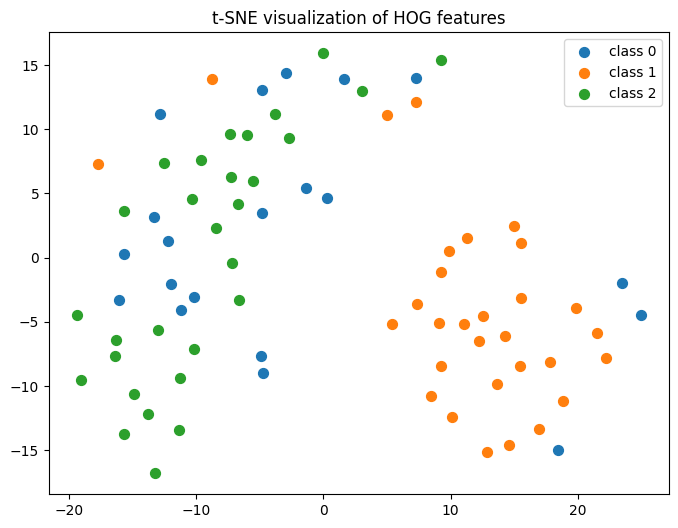

In [16]:
X_embedded = TSNE(
    n_components=2,
    perplexity=10,
    random_state=42
).fit_transform(train_hog)

plt.figure(figsize=(8, 6))
for c in np.unique(train_y):
    idx = train_y == c
    plt.scatter(X_embedded[idx, 0], X_embedded[idx, 1], label=f'class {c}', s=50)

plt.title("t-SNE visualization of HOG features")
plt.legend()
plt.show()

HOG distinction between Jesse and Michael:

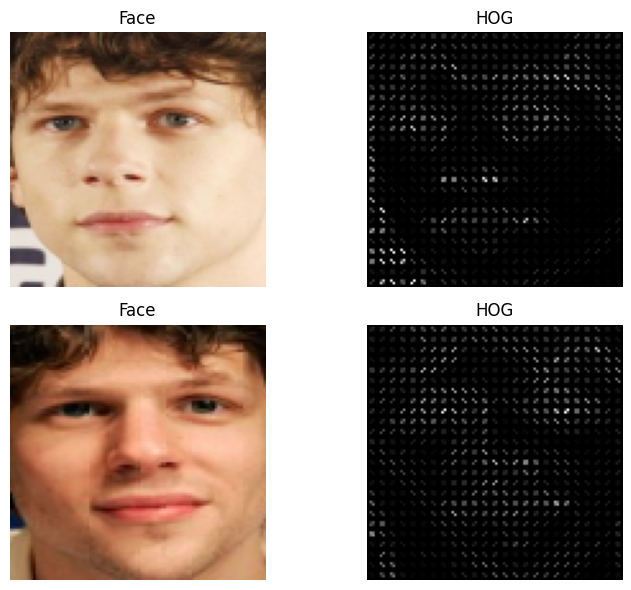

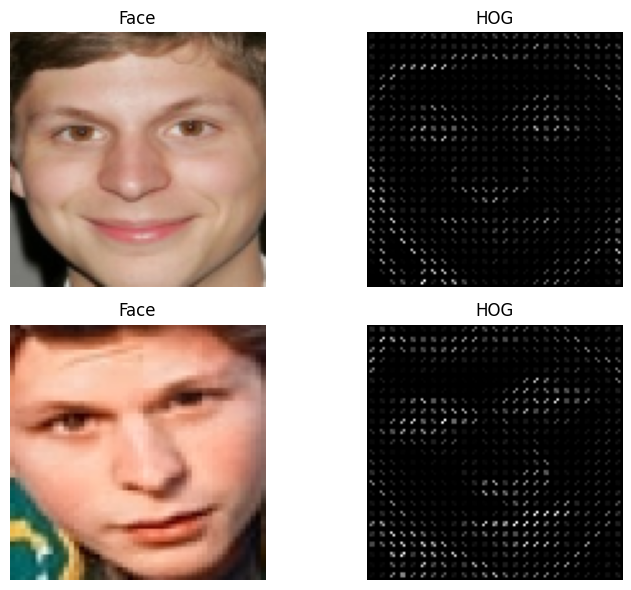

(None, None)

In [17]:
plot_hog_examples(train_X[train_y == 1], n=2),plot_hog_examples(train_X[train_y == 0], n=2)

HOG distinction between Mila and Sarah:

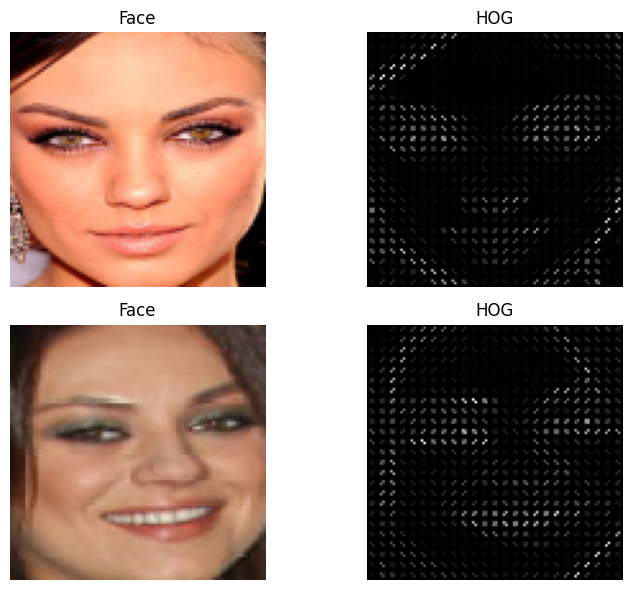

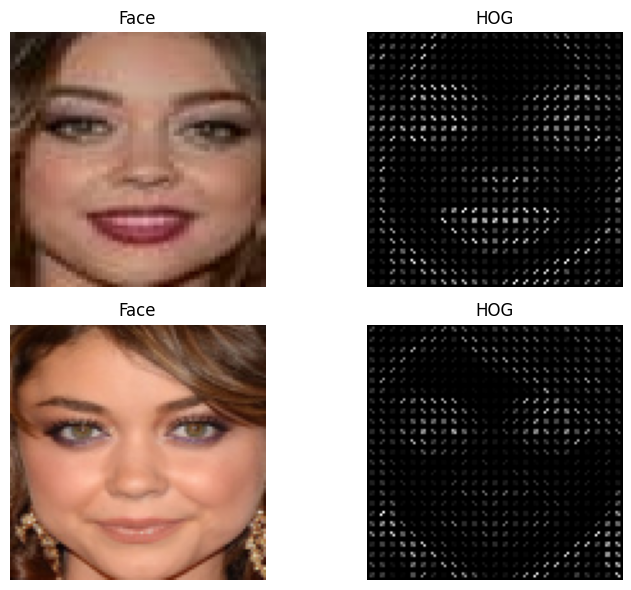

(None, None)

In [18]:
plot_hog_examples(train_X[train_y == 2], n=2), plot_hog_examples(train_X[train_y == 0][7:], n=2)

In [19]:
def plot_multiple_hog_tsne(X, y, configs, perplexity=10, random_state=42):
    n = len(configs)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5))
    
    if n == 1:
        axes = [axes]
    
    for ax, config in zip(axes, configs):
        extractor = HOGFeatureExtractor(
            orientations=config["orientations"],
            pixels_per_cell=config["pixels_per_cell"],
            cells_per_block=config["cells_per_block"],
            block_norm=config.get("block_norm", "L2-Hys")
        )
        
        features = extractor(X)
        
        X_embedded = TSNE(
            n_components=2,
            perplexity=perplexity,
            random_state=random_state
        ).fit_transform(features)
        
        for c in np.unique(y):
            idx = y == c
            ax.scatter(X_embedded[idx, 0], X_embedded[idx, 1], label=f"class {c}", s=40)
        
        ax.set_title(
            f"ori={config['orientations']}, "
            f"cell={config['pixels_per_cell']}, "
            f"block={config['cells_per_block']}"
        )
    
    axes[0].legend()
    plt.tight_layout()
    plt.show()

In [20]:
configs = [
    {"orientations": 9,  "pixels_per_cell": (8, 8), "cells_per_block": (2, 2)},
    {"orientations": 12, "pixels_per_cell": (8, 8), "cells_per_block": (2, 2)},
    {"orientations": 9,  "pixels_per_cell": (10, 10), "cells_per_block": (2, 2)},
    {"orientations": 12, "pixels_per_cell": (10, 10), "cells_per_block": (2, 2)},
    {"orientations": 9,  "pixels_per_cell": (8, 8), "cells_per_block": (8, 8)},
    {"orientations": 12, "pixels_per_cell": (8, 8), "cells_per_block": (8, 8)},
    {"orientations": 9,  "pixels_per_cell": (10, 10), "cells_per_block": (8, 8)},
    {"orientations": 12, "pixels_per_cell": (10, 10), "cells_per_block": (8, 8)},
]

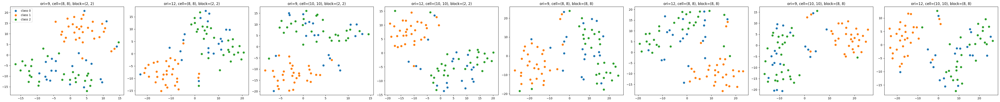

In [21]:
plot_multiple_hog_tsne(train_X, train_y, configs, perplexity=10, random_state=42)

In [22]:
hog_extractor = HOGFeatureExtractor(
    orientations=12,
    pixels_per_cell=(10, 10),
    cells_per_block=(2, 2)
)

train_hog = hog_extractor(train_X)
test_hog = hog_extractor(test_X)

print(train_hog.shape)
print(test_hog.shape)

(79, 3888)
(2735, 3888)


### 2.1.2 SIFT + VLAD

In [23]:
class SIFTVLADFeatureExtractor(IdentityFeatureExtractor):
    """
    SIFT + VLAD feature extractor.
    
    Workflow:
    1. Extract SIFT descriptors from all training images
    2. Fit a visual vocabulary (KMeans)
    3. Encode each image using VLAD
    
    Output dimensionality = n_clusters * 128
    because SIFT descriptors have dimension 128.
    """
    
    def __init__(self,
                 n_clusters=32,
                 max_features=500,
                 contrastThreshold=0.04,
                 edgeThreshold=10,
                 sigma=1.6,
                 random_state=42,
                 batch_size=1024,
                 power_norm=True,
                 intra_norm=True,
                 l2_norm=True):
        
        self.n_clusters = n_clusters
        self.power_norm = power_norm
        self.intra_norm = intra_norm
        self.l2_norm = l2_norm
        
        # SIFT parameters
        self.sift = cv2.SIFT_create(
            nfeatures=max_features,
            contrastThreshold=contrastThreshold,
            edgeThreshold=edgeThreshold,
            sigma=sigma
        )
        
        # Codebook / visual vocabulary
        self.kmeans = MiniBatchKMeans(
            n_clusters=n_clusters,
            random_state=random_state,
            batch_size=batch_size,
            n_init=10
        )
        
        self.is_fitted = False
    
    def _preprocess_image(self, img):
        """Ensure valid image type/range and convert to grayscale if needed."""
        img = np.clip(img, 0, 255).astype(np.uint8)
        
        if len(img.shape) == 3:
            gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        else:
            gray = img
            
        return gray
    
    def _extract_descriptors(self, img):
        """Extract SIFT descriptors from one image."""
        gray = self._preprocess_image(img)
        keypoints, descriptors = self.sift.detectAndCompute(gray, None)
        
        if descriptors is None:
            return np.empty((0, 128), dtype=np.float32)
        
        return descriptors.astype(np.float32)
    
    def fit(self, X):
        """
        Learn the VLAD codebook from training images.
        Must be called before transform().
        """
        all_descriptors = []
        
        for img in X:
            desc = self._extract_descriptors(img)
            if len(desc) > 0:
                all_descriptors.append(desc)
        
        if len(all_descriptors) == 0:
            raise ValueError("No SIFT descriptors found in any training image.")
        
        all_descriptors = np.vstack(all_descriptors)
        self.kmeans.fit(all_descriptors)
        self.is_fitted = True
        
        return self
    
    def _vlad_encode(self, descriptors):
        """Encode one image's SIFT descriptors into a VLAD vector."""
        K = self.n_clusters
        D = 128  # SIFT descriptor size
        
        vlad = np.zeros((K, D), dtype=np.float32)
        
        # If no descriptors were found, return zero vector
        if descriptors.shape[0] == 0:
            return vlad.ravel()
        
        centers = self.kmeans.cluster_centers_.astype(np.float32)
        labels = self.kmeans.predict(descriptors)
        
        # Accumulate residuals for each cluster
        for k in range(K):
            idx = labels == k
            if np.any(idx):
                residuals = descriptors[idx] - centers[k]
                vlad[k] = residuals.sum(axis=0)
        
        # Intra-normalization (per cluster block)
        if self.intra_norm:
            norms = np.linalg.norm(vlad, axis=1, keepdims=True) + 1e-12
            vlad = vlad / norms
        
        # Flatten
        vlad = vlad.ravel()
        
        # Power normalization (signed square root)
        if self.power_norm:
            vlad = np.sign(vlad) * np.sqrt(np.abs(vlad))
        
        # Global L2 normalization
        if self.l2_norm:
            vlad = vlad / (np.linalg.norm(vlad) + 1e-12)
        
        return vlad
    
    def transform(self, X):
        """Transform images into VLAD feature vectors."""
        if not self.is_fitted:
            raise ValueError("The VLAD extractor must be fitted before calling transform().")
        
        features = []
        
        for img in X:
            desc = self._extract_descriptors(img)
            feat = self._vlad_encode(desc)
            features.append(feat)
        
        return np.vstack(features)
    
    def fit_transform(self, X):
        """Fit the codebook and transform the same dataset."""
        self.fit(X)
        return self.transform(X)
    
    def __call__(self, X, fit=False):
        """
        Similar to your HOG style:
        - extractor(X) -> transform
        - extractor(X, fit=True) -> fit_transform
        """
        if fit:
            return self.fit_transform(X)
        return self.transform(X)

In [24]:
vlad_extractor = SIFTVLADFeatureExtractor(
    n_clusters=32,
    max_features=500
)

train_vlad = vlad_extractor(train_X, fit=True)
test_vlad = vlad_extractor(test_X)

print(train_vlad.shape)   # (n_train, 32 * 128)
print(test_vlad.shape)    # (n_test, 32 * 128)

(79, 4096)
(2735, 4096)


In [25]:
def plot_sift_examples(X, n=5, max_features=500):
    sift = cv2.SIFT_create(nfeatures=max_features)
    
    fig, axes = plt.subplots(n, 2, figsize=(8, 3 * n))
    
    for i in range(n):
        img = np.clip(X[i], 0, 255).astype(np.uint8)
        
        if len(img.shape) == 3:
            gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        else:
            gray = img
        
        keypoints, descriptors = sift.detectAndCompute(gray, None)
        kp_img = cv2.drawKeypoints(
            gray,
            keypoints,
            None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )
        
        if len(img.shape) == 2:
            axes[i, 0].imshow(img, cmap='gray')
        else:
            axes[i, 0].imshow(img)
        axes[i, 0].set_title("Face")
        axes[i, 0].axis("off")
        
        axes[i, 1].imshow(kp_img, cmap='gray')
        axes[i, 1].set_title(f"SIFT keypoints ({len(keypoints)})")
        axes[i, 1].axis("off")
    
    plt.tight_layout()
    plt.show()

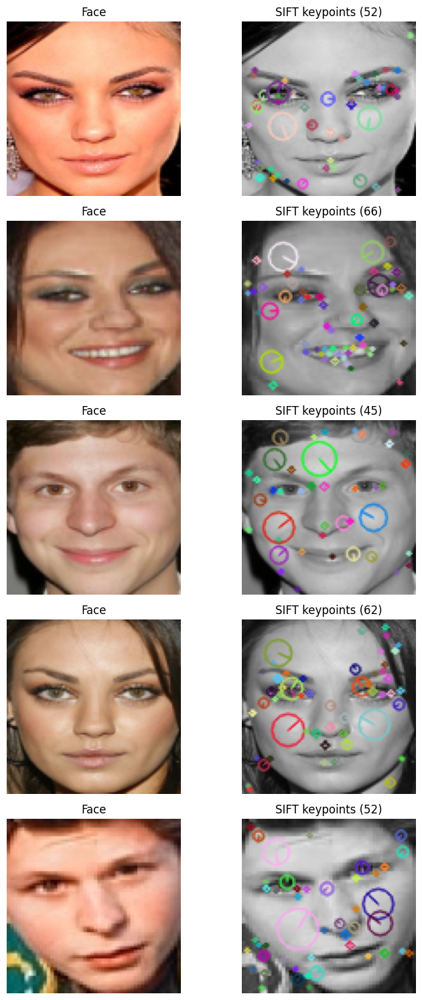

In [26]:
plot_sift_examples(train_X, n=5)

t-SNE visualisation of SIFT + VLAD features

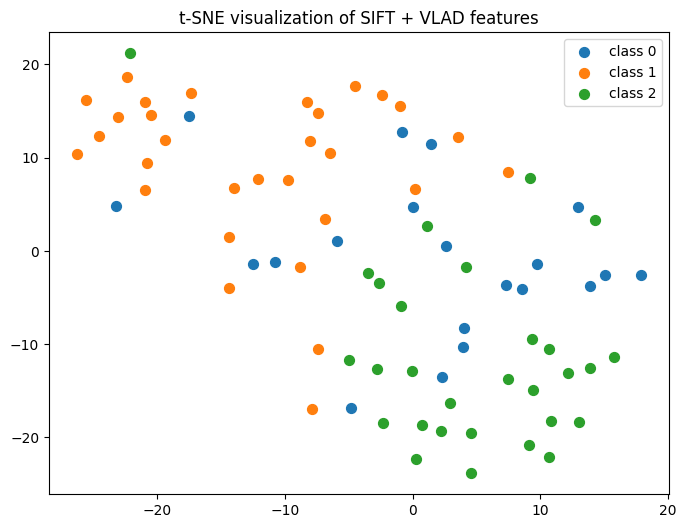

In [27]:
X_embedded = TSNE(
    n_components=2,
    perplexity=10,
    random_state=42
).fit_transform(train_vlad)

plt.figure(figsize=(8, 6))
for c in np.unique(train_y):
    idx = train_y == c
    plt.scatter(X_embedded[idx, 0], X_embedded[idx, 1], label=f'class {c}', s=50)

plt.title("t-SNE visualization of SIFT + VLAD features")
plt.legend()
plt.show()

### 2.1.3 Discussion Results: Handcrafted Features

**HOG (Section 2.1.1)** We can see from the t-SNE plot that there is a clear separation between most of the images from class 1 (Jesse) and the rest. Class 0 (Michael and Sarah) and class 2 (Mila) have a less obvious distinction. This could suggest that Sarah and Mila's faces look much more alike than Jesse and Michael's face. A possible explanation could be the eyes: the mascara, which is commonly worn in public events, creates a distinctive gradient orientation. Another possible explanation is the dissimilarity in the noses of Jesse and Michael.

Through t-SNE visualization of multiple HOG configurations, we found that an orientation of 12 with 10x10-pixel cells and 2x2-cell blocks gives the best sub-cluster separation for class 0, which is closer to class 2. We benefit from this sub-clustering when classifying lookalikes. With this increase in pixels per cell (from the initial 4x4), we also reduced the feature vector from 27,648 to 3,888 dimensions, reducing the risk of the curse of dimensionality (79 images vs. 3,888 features is already a high-dimensional setting).

Considering that we have 79 images and 3,888 dimensions, it is a good idea to further reduce dimensionality. We propose PCA and conduct an ablation study in Section 4 to demonstrate the improvement in classification performance.

**SIFT+VLAD (Section 2.2.2)** Clear features detected are the cheekbones, wrinkles, and thick lines such as the eyebrows, the lip line, and the eyelashes. However, the separation between classes in the t-SNE visualization is of worse quality than HOG. This is confirmed in later sections by the classifier performance. SIFT is designed for general keypoint matching rather than identity-discriminative representations, and a vocabulary of 32 clusters may not capture enough face-specific structure at this dataset size.

## 2.2. Baseline: PCA (Eigenfaces)

As an alternative to handcrafted descriptors, we learn a feature representation directly from the training data using Principal Component Analysis (PCA), the so-called *eigenface* approach.

**Converting images to a 2D matrix.** Each face image is first converted to grayscale, reducing it from 100x100x3 to 100x100 = 10,000 values. Each image is then flattened to a row vector, giving a data matrix X of shape (N, 10,000) where N is the number of training samples. We work in grayscale as color adds 3x more dimensions but contributes little to identity discrimination for this task.

**Exploiting dimensionality.** With N=79 training samples and 10,000 pixel dimensions, the covariance matrix X^T X would be 10,000x10,000, expensive to compute. Instead we exploit the fact that the non-zero eigenvalues of X^T X and X X^T are identical, and X X^T is only 79x79. Sklearn's PCA uses SVD internally, which implicitly exploits this: it factorises X = U S V^T and extracts eigenvectors from the smaller matrix, keeping computations tractable. As a result, the maximum number of non-zero eigenvalues is bounded by N-1 = 78, regardless of the image resolution.

**Mean subtraction.** As discussed in the lecture, any face image can be expressed as:

    x = mu + w1*v1 + w2*v2 + ... + wp*vp

Since we are interested in what *differentiates* faces rather than what they share, we explicitly subtract the mean face before fitting PCA. The mean is computed on the training images only and reused when processing new images; computing a new mean on test data would be methodologically incorrect as the model should have no prior knowledge of unseen images.

**Eigenvalue vs SVD.** We use Singular Value Decomposition (SVD) via sklearn's `PCA`, rather than explicitly computing the eigendecomposition of the covariance matrix. SVD is numerically more stable and more efficient, especially when N << D, and yields identical principal components. Whitening is applied so all components are on a comparable scale for downstream classification.

**Choosing p.** We first fit PCA retaining all 78 possible components and inspect the cumulative explained variance curve. The first component alone explains ~19.93% of the variance, reflecting a dominant lighting axis, after which variance drops off steadily. Cumulative variance reaches 90% at **p = 36**, which we adopt as our operating point. This reduces the feature space from 10,000 dimensions to just 36 while retaining 90% of the variance. The remaining 41 components are assumed to capture noise and are discarded.

The choice of a 90% variance threshold represents a trade-off between dimensionality reduction and information retention, supported by the observation that eigenvalues in facial datasets typically decrease exponentially. Research indicates that approximately 90% of the total variance is captured within the first few dimensions (Naim, 2015), which in this project allowed for the preservation of meaningful facial structures using only 36 components. Empirical studies suggest that components beyond this 90% threshold often contribute to computational redundancy rather than recognition accuracy, acting as noise (Ahmed et al., 2023).

### 2.2.1 PCA Implementation

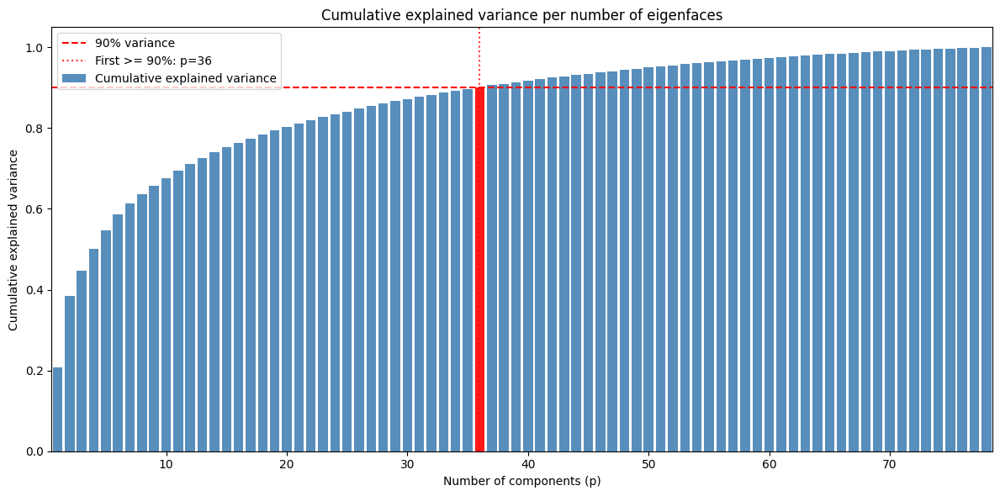

,Eigenvalue,Variance explained (%),Cumulative variance (%)
Component,,,
1,4425550.02,20.68,20.68
2,3822279.76,17.86,38.54
3,1338775.08,6.26,44.80
4,1154683.25,5.40,50.19
5,959070.46,4.48,54.67
6,846039.33,3.95,58.63
7,565677.73,2.64,61.27
8,523350.99,2.45,63.72
9,435695.88,2.04,65.75


Optimal number of components: p=36 (>= 90% variance explained)
test_X_pca  : (2735, 36)


In [28]:
class PCAFeatureExtractor(IdentityFeatureExtractor):
    """PCA-based feature extractor (eigenfaces).
    
    Converts images to grayscale before fitting PCA, following the classical
    eigenface approach. Explicitly subtracts the mean face before fitting,
    following the eigenface formulation: x = μ + w₁·v₁ + ... + wₚ·vₚ.
    The mean is computed on the training set and reused when processing new images.
    
    If n_components is None, the optimal p is determined automatically by
    fitting with all possible components first and selecting the smallest p
    that explains at least variance_threshold of the total variance.
    """

    def __init__(self, n_components=None, variance_threshold=0.90, whiten=True, verbose=True):
        self.n_components = n_components
        self.variance_threshold = variance_threshold
        self.whiten = whiten
        self.verbose = verbose
        self.pca = None
        self.mean_face = None

    def _to_flat(self, X):
        """Convert to grayscale and flatten to (N, H*W)."""
        X_gray = np.array([cv2.cvtColor(img.astype(np.uint8), cv2.COLOR_RGB2GRAY)
                           for img in X])
        return X_gray.reshape(X_gray.shape[0], -1).astype(np.float64)

    def _find_optimal_components(self, X_centered, n_max):
        """Fit PCA with all components, plot variance curve, return optimal p."""
        pca_full = PCA(n_components=n_max)
        pca_full.fit(X_centered)

        cumvar = np.cumsum(pca_full.explained_variance_ratio_)
        x = np.arange(1, len(cumvar) + 1)
        over_idx = np.where(cumvar >= self.variance_threshold)[0]
        first_over_idx = int(over_idx[0]) if len(over_idx) > 0 else len(cumvar) - 1
        optimal_p = int(x[first_over_idx])

        if not self.verbose:
            return optimal_p

        # Plot
        bar_colors = ['steelblue'] * len(cumvar)
        bar_colors[first_over_idx] = 'red'
        plt.figure(figsize=(12, 6))
        plt.bar(x, cumvar, width=0.8, color=bar_colors, alpha=0.9,
                label='Cumulative explained variance')
        plt.axhline(self.variance_threshold, linestyle='--', color='r',
                    label=f'{int(self.variance_threshold*100)}% variance')
        plt.axvline(optimal_p, linestyle=':', color='r', alpha=0.8,
                    label=f'First >= {int(self.variance_threshold*100)}%: p={optimal_p}')
        plt.xlabel('Number of components (p)')
        plt.ylabel('Cumulative explained variance')
        plt.title('Cumulative explained variance per number of eigenfaces')
        plt.ylim(0, 1.05)
        plt.xlim(0.5, len(cumvar) + 0.5)
        for tick_label in plt.gca().get_xticklabels():
            try:
                val = int(float(tick_label.get_text()))
            except ValueError:
                continue
            if val == optimal_p:
                tick_label.set_color('red')
                tick_label.set_fontweight('bold')
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Variance table
        variance_table = pd.DataFrame({
            'Component':               range(1, len(pca_full.explained_variance_ratio_) + 1),
            'Eigenvalue':              pca_full.explained_variance_.round(2),
            'Variance explained (%)':  (pca_full.explained_variance_ratio_ * 100).round(2),
            'Cumulative variance (%)': (np.cumsum(pca_full.explained_variance_ratio_) * 100).round(2)
        })
        variance_table.set_index('Component', inplace=True)
        display(variance_table.head(40))

        return optimal_p

    def fit(self, X):
        X_flat = self._to_flat(X)

        # Explicitly store and subtract the mean face
        self.mean_face = X_flat.mean(axis=0)
        X_centered = X_flat - self.mean_face

        # Determine optimal p if not specified
        if self.n_components is None:
            n_max = min(len(X) - 1, 79)
            self.n_components = self._find_optimal_components(X_centered, n_max)
            if self.verbose:
                print(f"Optimal number of components: p={self.n_components} "
                      f"(>= {int(self.variance_threshold*100)}% variance explained)")

        self.pca = PCA(n_components=self.n_components, whiten=self.whiten)
        self.pca.fit(X_centered)
        return self

    def transform(self, X):
        if len(X.shape) == 3:
            X = np.expand_dims(X, axis=0)
        X_flat = self._to_flat(X)
        return self.pca.transform(X_flat - self.mean_face)

    def inverse_transform(self, X_projected):
        """Reconstruct faces from PCA scores by adding back the mean face."""
        return self.pca.inverse_transform(X_projected) + self.mean_face


# Fit — automatically determines optimal p and shows variance plot + table
pca_extractor = PCAFeatureExtractor(variance_threshold=0.90)
pca_extractor.fit(train_X)
train_X_pca = pca_extractor.transform(train_X)
test_X_pca = pca_extractor.transform(test_X)
print(f"test_X_pca  : {test_X_pca.shape}")

### 2.2.2 Eigenface Visualisations

The first 36 eigenfaces are shown below (see discussion for interpretation).

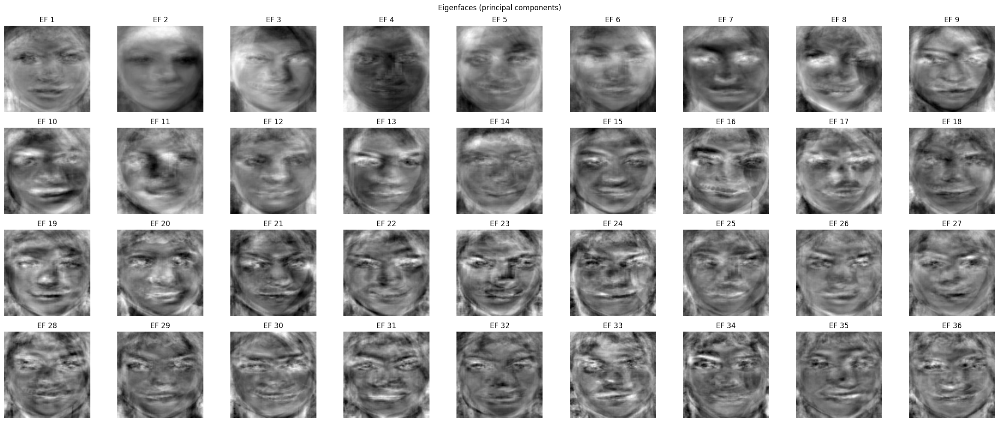

In [29]:
# Visualization 1 — Visualize the 36 eigenfaces (principal components)
face_shape = (100, 100)
n_components = pca_extractor.n_components  # 36
n_cols = 9
n_rows = int(np.ceil(n_components / n_cols))  # 5 rows, last row partially filled

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, n_rows * 2.5))
for i, ax in enumerate(axes.flat):
    if i < n_components:
        eigenface = pca_extractor.pca.components_[i].reshape(face_shape)
        ax.imshow(eigenface, cmap='gray')
        ax.set_title(f'EF {i+1}')
    ax.axis('off')
plt.suptitle('Eigenfaces (principal components)')
plt.tight_layout()
plt.show()

### 2.2.3 Face Reconstruction

Reconstructions using an increasing number of eigenfaces (see discussion for interpretation).

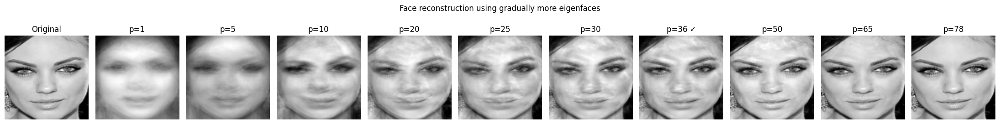

In [30]:
# Visualization 2 — reconstruct a face using gradually more eigenfaces
face_shape = (100, 100)
p_values = [1, 5, 10, 20, 25, 30, 36, 50,65, 78]

X_gray = np.array([cv2.cvtColor(img.astype(np.uint8), cv2.COLOR_RGB2GRAY)
                   for img in train_X])

fig, axes = plt.subplots(1, len(p_values) + 1, figsize=(22, 3))

axes[0].imshow(X_gray[0], cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

for i, p in enumerate(p_values):
    # Fit a temporary PCA with p components, no whitening, using extractor's mean
    pca_temp = PCA(n_components=p, whiten=False)
    X_flat = X_gray.reshape(len(X_gray), -1).astype(np.float64)
    X_centered = X_flat - pca_extractor.mean_face
    pca_temp.fit(X_centered)

    # Project and reconstruct using inverse_transform
    score = pca_temp.transform(X_centered[0:1])
    reconstructed = pca_temp.inverse_transform(score) + pca_extractor.mean_face

    ax = axes[i + 1]
    ax.imshow(np.clip(reconstructed.reshape(face_shape), 0, 255), cmap='gray')
    ax.set_title(f'p={p}' + (' ✓' if p == pca_extractor.n_components else ''))
    ax.axis('off')

plt.suptitle('Face reconstruction using gradually more eigenfaces')
plt.tight_layout()
plt.show()

### 2.2.4 Feature Space Plots

PCA feature space visualised using the first two principal components (see discussion for interpretation).

Valid images: 79 / 79


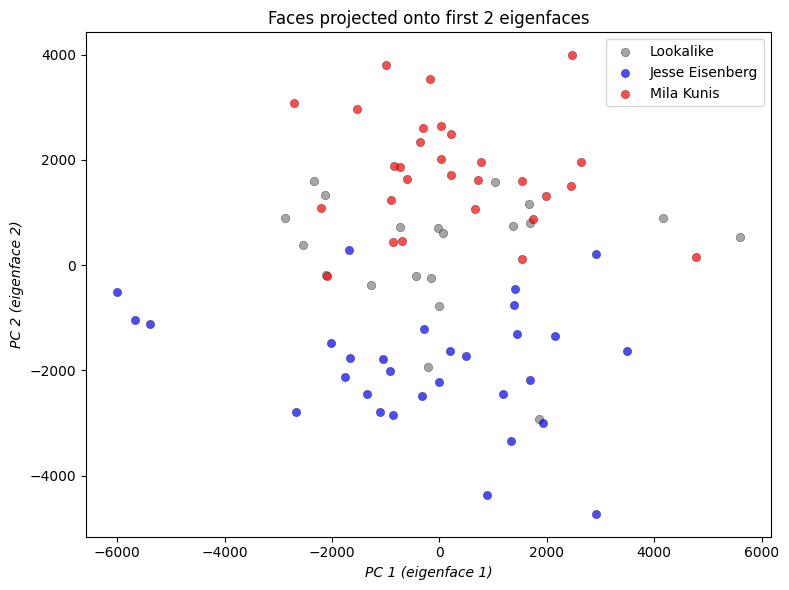

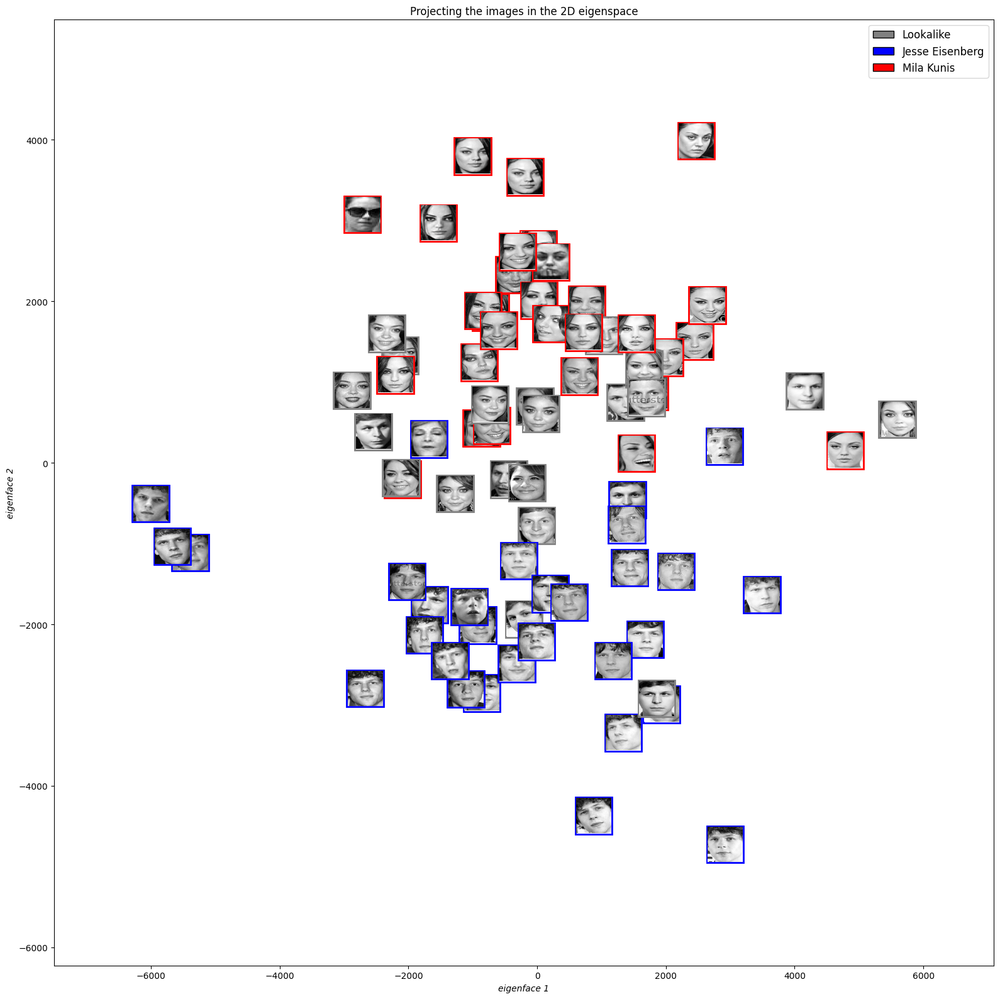

In [31]:
face_shape = (100, 100)

# Filter out any broken images
X_flat_raw = train_X.reshape(len(train_X), -1).astype(np.float64)
valid_mask = X_flat_raw.min(axis=1) >= 0
print(f"Valid images: {valid_mask.sum()} / {len(train_X)}")
if (~valid_mask).any():
    print(f"Broken image indices: {np.where(~valid_mask)[0]}")

X_valid = train_X[valid_mask]
y_valid = train_y[valid_mask]

# Project onto first 2 components for visualisation using the fitted extractor
# Note: only used for visualisation, classification uses all 36 components
pca_2d = PCA(n_components=2)
X_gray = np.array([cv2.cvtColor(img.astype(np.uint8), cv2.COLOR_RGB2GRAY)
                   for img in X_valid])
X_centered = X_gray.reshape(len(X_gray), -1).astype(np.float64) - pca_extractor.mean_face
coords = pca_2d.fit_transform(X_centered)

class_info = [(0, 'Lookalike', 'gray'), (1, 'Jesse Eisenberg', 'blue'), (2, 'Mila Kunis', 'red')]

# Plot 1 — scatter plot with class labels
fig, ax = plt.subplots(figsize=(8, 6))
for label, name, color in class_info:
    mask = y_valid == label
    ax.scatter(coords[mask, 0], coords[mask, 1],
               label=name, c=color, alpha=0.7, edgecolors='k', linewidths=0.3)
ax.set_xlabel('PC 1 (eigenface 1)', style='italic')
ax.set_ylabel('PC 2 (eigenface 2)', style='italic')
ax.set_title('Faces projected onto first 2 eigenfaces')
ax.legend()
plt.tight_layout()
plt.show()

# Plot 2 — image plot with actual face thumbnails
fig, ax = plt.subplots(figsize=(16, 16))
border_colors = {0: 'gray', 1: 'blue', 2: 'red'}
for i in range(len(X_gray)):
    imagebox = OffsetImage(X_gray[i].reshape(face_shape), zoom=0.4, cmap='gray')
    ab = AnnotationBbox(imagebox, (coords[i, 0], coords[i, 1]),
                        frameon=True, pad=0.1,
                        bboxprops=dict(edgecolor=border_colors[y_valid[i]], linewidth=2))
    ax.add_artist(ab)

padding = 1500
ax.set_xlim(coords[:, 0].min() - padding, coords[:, 0].max() + padding)
ax.set_ylim(coords[:, 1].min() - padding, coords[:, 1].max() + padding)
ax.set_xlabel('eigenface 1', style='italic')
ax.set_ylabel('eigenface 2', style='italic')
ax.set_title('Projecting the images in the 2D eigenspace')


legend_elements = [Patch(facecolor=color, edgecolor='k', label=name)
                   for _, name, color in class_info]
ax.legend(handles=legend_elements, loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()

### 2.2.5 Discussion Results: PCA

PCA achieves strong dimensionality reduction from 10,000 to 36 dimensions while retaining 90% of the variance. This threshold is justified by the exponential decay of eigenvalues typical in face datasets: research indicates that ~90% of the variance is captured within the first few components (Naim, 2015), and components beyond this point tend to contribute noise rather than identity-relevant structure (Ahmed et al., 2023). Retaining 36 components also reduces the risk of overfitting on our small dataset of 79 training samples.

**Eigenface visualisations (Section 2.2.2).** Each eigenface is a principal component reshaped back into image form. The earliest components capture global, low-frequency structure, overall illumination and broad facial shape, while later components encode increasingly fine-grained local detail. This is consistent with the variance curve: the first few components do the heavy lifting and subsequent ones contribute progressively less.

**Face reconstruction (Section 2.2.3).** To validate our choice of p=36, we reconstruct a training face using an increasing number of eigenfaces. At p=1 only a blurry brightness silhouette is recovered; at p=78 (the maximum) the reconstruction is perfect. At p=36 the face is already recognisable but still blurry in sharp edges and local texture — the remaining 10% of variance contains perceptually important high-frequency detail. For classification this is an acceptable trade-off: the 36 components capture the dominant axes of variation that differentiate identities, while retaining the noisy tail components would risk overfitting.

**Feature space plots (Section 2.2.4).** The scatter plot shows reasonable class separation in the 2D eigenspace. Jesse (blue) and Mila (red) form largely distinct clusters, while the lookalikes (gray) fall close to their respective celebrity, Michael Cera near Jesse and Sarah Hyland near Mila, confirming that PCA encodes facial similarity but may struggle with fine-grained lookalike discrimination. Note that only the first two components (~38% of variance) are used for visualisation, the actual classification uses all 36. Eigenface 1 (horizontal axis) correlates with lighting conditions, while Eigenface 2 (vertical axis) appears to capture gender, consistent with the fact that lighting and gender are the dominant axes of variation in a mixed-gender dataset, rather than finer identity-specific features.

Compared to handcrafted features, PCA is fully data-driven with no manual parameter choices beyond the variance threshold. However, it is not optimised for face identity: it captures whatever dominates the pixel space, which may not be the most discriminative axes for classification.

## 2.3. State-of-the-Art Embeddings

We evaluate three deep learning face recognition models via the DeepFace library. Since faces are already cropped by YuNet, internal face detection is bypassed with `detector_backend='skip'` in all three.

**FaceNet512 (Section 2.3.1)** extracts 512-dimensional embeddings trained end-to-end for face verification, encoding identity-discriminative information by design without any additional feature engineering.

**ArcFace (Section 2.3.2)** (Additive Angular Margin Loss) also produces 512-dimensional embeddings. Its key mechanism is a geometric optimization of the feature space (Deng et al., 2019): all embedding vectors are normalized to unit length, so identities live on a hypersphere where similarity is measured by angle rather than Euclidean distance. During training, ArcFace adds a fixed angular margin penalty *m* to the angle between each embedding and its correct class center before computing the loss. This forces the network to produce embeddings that are angularly closer to the correct class center, resulting in tighter intra-class clusters and wider inter-class gaps, directly benefiting downstream classification.

**VGG-Face (Section 2.3.3)** produces 4,096-dimensional embeddings but is excluded as a fair baseline: our dataset is a subset of the VGGFace training set, so the model may have seen these exact images during training. This data overlap inflates performance (submitted score: 94%) in a way that would not generalise to truly unseen faces. We include it for completeness only.

### 2.3.1 FaceNet512

In [32]:
# ── Weights: Kaggle dataset or HuggingFace fallback ──────────────────────────
# On Kaggle: add dataset  ruicampos/facenet-512-weights-deepface  to your notebook.
kaggle_path   = '/kaggle/input/facenet-512-weights-deepface/facenet512_weights.h5'
deepface_path = os.path.expanduser('~/.deepface/weights/facenet512_weights.h5')
hf_url        = 'https://huggingface.co/WePrompt/deepface-weights/resolve/main/facenet512_weights.h5'

os.makedirs(os.path.dirname(deepface_path), exist_ok=True)

if os.path.exists(kaggle_path):
    shutil.copy2(kaggle_path, deepface_path)
    print('Weights loaded from Kaggle dataset.')
else:
    print('Downloading facenet512 weights from HuggingFace...')
    subprocess.run(['curl', '-L', '--progress-bar', '-o', deepface_path, hf_url], check=True)
    size_mb = os.path.getsize(deepface_path) / 1e6
    print(f'Downloaded: {size_mb:.1f} MB')
    if size_mb < 50:
        raise RuntimeError(f'Download looks corrupt ({size_mb:.1f} MB, expected ~96 MB).')

# ── Embedding cache directory (persists within a Kaggle session) ─────────────
EMBED_CACHE_DIR = '/kaggle/working/embed_cache' if os.path.exists('/kaggle') else '/tmp/embed_cache'
os.makedirs(EMBED_CACHE_DIR, exist_ok=True)

# ── Build model once — reused by all batch calls ─────────────────────────────
# DeepFace returns a wrapper object; the Keras model is at .model
_facenet_client = DeepFace.build_model('Facenet512')
_facenet_model  = _facenet_client.model

class FaceNetFeatureExtractor(IdentityFeatureExtractor):
    """
    512-d FaceNet embeddings using batch inference on the underlying Keras model.
    10-20x faster than calling DeepFace.represent() per image.
    Results are cached to disk so re-runs within a session are instant.
    """
    BATCH_SIZE  = 64
    TARGET_SIZE = (160, 160)

    @staticmethod
    def _preprocess(img):
        """Resize to 160x160 and standardise per-image (FaceNet convention)."""
        img = cv2.resize(np.clip(img, 0, 255).astype('float32'), (160, 160))
        mean, std = img.mean(), img.std()
        return (img - mean) / (std + 1e-6)

    def transform(self, X, cache_key=None):
        if cache_key:
            cache_path = os.path.join(EMBED_CACHE_DIR, f'facenet_{cache_key}.npy')
            if os.path.exists(cache_path):
                print(f"  [FaceNet] loading from cache ({cache_key})...")
                return np.load(cache_path)

        n, all_embs = len(X), []
        for start in range(0, n, self.BATCH_SIZE):
            batch  = X[start : start + self.BATCH_SIZE]
            prep   = np.stack([self._preprocess(img) for img in batch])
            embs   = _facenet_model.predict(prep, verbose=0)
            norms  = np.linalg.norm(embs, axis=1, keepdims=True)
            all_embs.append(embs / (norms + 1e-10))
            print(f"  [FaceNet] {min(start + self.BATCH_SIZE, n)}/{n}")

        result = np.vstack(all_embs).astype(np.float32)

        if cache_key:
            np.save(cache_path, result)
            print(f"  [FaceNet] saved to cache ({cache_key})")

        return result

    def __call__(self, X, fit=False, cache_key=None):
        return self.transform(X, cache_key=cache_key)


facenet_extractor = FaceNetFeatureExtractor()
train_facenet = facenet_extractor(train_X, cache_key='train')
test_facenet  = facenet_extractor(test_X,  cache_key='test')
print(f"train_facenet : {train_facenet.shape}")
print(f"test_facenet  : {test_facenet.shape}")

######################################################################## 100.0%


Downloaded: 95.0 MB


I0000 00:00:1775599478.708213      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15253 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1775599484.141718      98 cuda_dnn.cc:529] Loaded cuDNN version 91002


  [FaceNet] 64/79
  [FaceNet] 79/79
  [FaceNet] saved to cache (train)
  [FaceNet] 64/2735
  [FaceNet] 128/2735
  [FaceNet] 192/2735
  [FaceNet] 256/2735
  [FaceNet] 320/2735
  [FaceNet] 384/2735
  [FaceNet] 448/2735
  [FaceNet] 512/2735
  [FaceNet] 576/2735
  [FaceNet] 640/2735
  [FaceNet] 704/2735
  [FaceNet] 768/2735
  [FaceNet] 832/2735
  [FaceNet] 896/2735
  [FaceNet] 960/2735
  [FaceNet] 1024/2735
  [FaceNet] 1088/2735
  [FaceNet] 1152/2735
  [FaceNet] 1216/2735
  [FaceNet] 1280/2735
  [FaceNet] 1344/2735
  [FaceNet] 1408/2735
  [FaceNet] 1472/2735
  [FaceNet] 1536/2735
  [FaceNet] 1600/2735
  [FaceNet] 1664/2735
  [FaceNet] 1728/2735
  [FaceNet] 1792/2735
  [FaceNet] 1856/2735
  [FaceNet] 1920/2735
  [FaceNet] 1984/2735
  [FaceNet] 2048/2735
  [FaceNet] 2112/2735
  [FaceNet] 2176/2735
  [FaceNet] 2240/2735
  [FaceNet] 2304/2735
  [FaceNet] 2368/2735
  [FaceNet] 2432/2735
  [FaceNet] 2496/2735
  [FaceNet] 2560/2735
  [FaceNet] 2624/2735
  [FaceNet] 2688/2735
  [FaceNet] 2735/2735

### 2.3.2 ArcFace

In [33]:
_arcface_client = DeepFace.build_model('ArcFace')
_arcface_model  = _arcface_client.model

class ArcFaceExtractor(IdentityFeatureExtractor):
    """
    512-d ArcFace embeddings using batch inference on the underlying Keras model.
    10-20x faster than calling DeepFace.represent() per image.
    Results are cached to disk so re-runs within a session are instant.
    """
    BATCH_SIZE  = 64
    TARGET_SIZE = (112, 112)

    @staticmethod
    def _preprocess(img):
        """Resize to 112x112 and normalise to [-1, 1] (ArcFace convention)."""
        img = cv2.resize(np.clip(img, 0, 255).astype('float32'), (112, 112))
        return (img / 127.5) - 1.0

    def transform(self, X, cache_key=None):
        if cache_key:
            cache_path = os.path.join(EMBED_CACHE_DIR, f'arcface_{cache_key}.npy')
            if os.path.exists(cache_path):
                print(f"  [ArcFace] loading from cache ({cache_key})...")
                return np.load(cache_path)

        n, all_embs = len(X), []
        for start in range(0, n, self.BATCH_SIZE):
            batch  = X[start : start + self.BATCH_SIZE]
            prep   = np.stack([self._preprocess(img) for img in batch])
            embs   = _arcface_model.predict(prep, verbose=0)
            norms  = np.linalg.norm(embs, axis=1, keepdims=True)
            all_embs.append(embs / (norms + 1e-10))
            print(f"  [ArcFace] {min(start + self.BATCH_SIZE, n)}/{n}")

        result = np.vstack(all_embs).astype(np.float32)

        if cache_key:
            np.save(cache_path, result)
            print(f"  [ArcFace] saved to cache ({cache_key})")

        return result

    def __call__(self, X, fit=False, cache_key=None):
        return self.transform(X, cache_key=cache_key)


arcface_extractor = ArcFaceExtractor()
train_arcface = arcface_extractor(train_X, cache_key='train')
test_arcface  = arcface_extractor(test_X,  cache_key='test')
print(f"train_arcface : {train_arcface.shape}")
print(f"test_arcface  : {test_arcface.shape}")

26-04-07 22:04:59 - 🔗 arcface_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5 to /root/.deepface/weights/arcface_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.h5
To: /root/.deepface/weights/arcface_weights.h5
100%|██████████| 137M/137M [00:00<00:00, 271MB/s]


  [ArcFace] 64/79
  [ArcFace] 79/79
  [ArcFace] saved to cache (train)
  [ArcFace] 64/2735
  [ArcFace] 128/2735
  [ArcFace] 192/2735
  [ArcFace] 256/2735
  [ArcFace] 320/2735
  [ArcFace] 384/2735
  [ArcFace] 448/2735
  [ArcFace] 512/2735
  [ArcFace] 576/2735
  [ArcFace] 640/2735
  [ArcFace] 704/2735
  [ArcFace] 768/2735
  [ArcFace] 832/2735
  [ArcFace] 896/2735
  [ArcFace] 960/2735
  [ArcFace] 1024/2735
  [ArcFace] 1088/2735
  [ArcFace] 1152/2735
  [ArcFace] 1216/2735
  [ArcFace] 1280/2735
  [ArcFace] 1344/2735
  [ArcFace] 1408/2735
  [ArcFace] 1472/2735
  [ArcFace] 1536/2735
  [ArcFace] 1600/2735
  [ArcFace] 1664/2735
  [ArcFace] 1728/2735
  [ArcFace] 1792/2735
  [ArcFace] 1856/2735
  [ArcFace] 1920/2735
  [ArcFace] 1984/2735
  [ArcFace] 2048/2735
  [ArcFace] 2112/2735
  [ArcFace] 2176/2735
  [ArcFace] 2240/2735
  [ArcFace] 2304/2735
  [ArcFace] 2368/2735
  [ArcFace] 2432/2735
  [ArcFace] 2496/2735
  [ArcFace] 2560/2735
  [ArcFace] 2624/2735
  [ArcFace] 2688/2735
  [ArcFace] 2735/2735

t-SNE visualization ArcFace embeddings

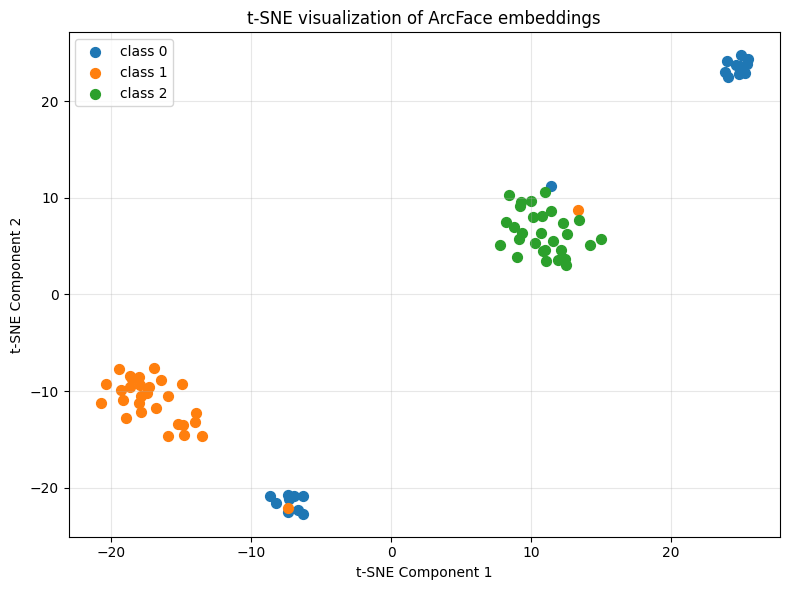

In [34]:
def visualize_arcface_tsne(embeddings, labels, title="ArcFace Embeddings (t-SNE)"):
    """Visualize ArcFace embeddings using t-SNE, consistent with HOG and VLAD plots."""
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=10)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    plt.figure(figsize=(8, 6))
    for c in np.unique(labels):
        idx = labels == c
        plt.scatter(embeddings_2d[idx, 0], embeddings_2d[idx, 1], 
                   label=f'class {c}', s=50)
    
    plt.title(title)
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

visualize_arcface_tsne(train_arcface, train_y, 
                       "t-SNE visualization of ArcFace embeddings")

### 2.3.3 VGG-Face

In [35]:
_vggface_client = DeepFace.build_model('VGG-Face')
_vggface_model  = _vggface_client.model

class VGGFaceExtractor(IdentityFeatureExtractor):
    """
    4096-d VGG-Face embeddings using batch inference on the underlying Keras model.
    Results are cached to disk so re-runs within a session are instant.
    """
    BATCH_SIZE  = 32
    TARGET_SIZE = (224, 224)

    @staticmethod
    def _preprocess(img):
        """Resize to 224x224 and apply VGG mean subtraction (VGG-Face convention)."""
        img = cv2.resize(np.clip(img, 0, 255).astype('float32'), (224, 224))
        img -= np.array([93.5940, 104.7624, 129.1863])  # BGR mean subtraction
        return img

    def transform(self, X, cache_key=None):
        if cache_key:
            cache_path = os.path.join(EMBED_CACHE_DIR, f'vggface_{cache_key}.npy')
            if os.path.exists(cache_path):
                print(f"  [VGG-Face] loading from cache ({cache_key})...")
                return np.load(cache_path)

        n, all_embs = len(X), []
        for start in range(0, n, self.BATCH_SIZE):
            batch  = X[start : start + self.BATCH_SIZE]
            prep   = np.stack([self._preprocess(img) for img in batch])
            embs   = _vggface_model.predict(prep, verbose=0)
            norms  = np.linalg.norm(embs, axis=1, keepdims=True)
            all_embs.append(embs / (norms + 1e-10))
            print(f"  [VGG-Face] {min(start + self.BATCH_SIZE, n)}/{n}")

        result = np.vstack(all_embs).astype(np.float32)

        if cache_key:
            np.save(cache_path, result)
            print(f"  [VGG-Face] saved to cache ({cache_key})")

        return result

    def __call__(self, X, fit=False, cache_key=None):
        return self.transform(X, cache_key=cache_key)


vggface_extractor = VGGFaceExtractor()
train_vggface = vggface_extractor(train_X, cache_key='train')
test_vggface  = vggface_extractor(test_X,  cache_key='test')
print(f"train_vggface : {train_vggface.shape}")
print(f"test_vggface  : {test_vggface.shape}")

26-04-07 22:05:15 - 🔗 vgg_face_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5 to /root/.deepface/weights/vgg_face_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.h5
To: /root/.deepface/weights/vgg_face_weights.h5
100%|██████████| 580M/580M [00:03<00:00, 149MB/s]


  [VGG-Face] 32/79
  [VGG-Face] 64/79
  [VGG-Face] 79/79
  [VGG-Face] saved to cache (train)
  [VGG-Face] 32/2735
  [VGG-Face] 64/2735
  [VGG-Face] 96/2735
  [VGG-Face] 128/2735
  [VGG-Face] 160/2735
  [VGG-Face] 192/2735
  [VGG-Face] 224/2735
  [VGG-Face] 256/2735
  [VGG-Face] 288/2735
  [VGG-Face] 320/2735
  [VGG-Face] 352/2735
  [VGG-Face] 384/2735
  [VGG-Face] 416/2735
  [VGG-Face] 448/2735
  [VGG-Face] 480/2735
  [VGG-Face] 512/2735
  [VGG-Face] 544/2735
  [VGG-Face] 576/2735
  [VGG-Face] 608/2735
  [VGG-Face] 640/2735
  [VGG-Face] 672/2735
  [VGG-Face] 704/2735
  [VGG-Face] 736/2735
  [VGG-Face] 768/2735
  [VGG-Face] 800/2735
  [VGG-Face] 832/2735
  [VGG-Face] 864/2735
  [VGG-Face] 896/2735
  [VGG-Face] 928/2735
  [VGG-Face] 960/2735
  [VGG-Face] 992/2735
  [VGG-Face] 1024/2735
  [VGG-Face] 1056/2735
  [VGG-Face] 1088/2735
  [VGG-Face] 1120/2735
  [VGG-Face] 1152/2735
  [VGG-Face] 1184/2735
  [VGG-Face] 1216/2735
  [VGG-Face] 1248/2735
  [VGG-Face] 1280/2735
  [VGG-Face] 1312/273

### Discussion: Deep Embeddings

ArcFace and FaceNet both produce compact, identity-focused 512-dimensional embeddings and outperform HOG and SIFT+VLAD in downstream classification. The t-SNE plot of ArcFace shows tighter and better-separated clusters, consistent with its angular margin training objective: by forcing smaller intra-class angles and larger inter-class angles during training, the model produces a feature space where identities are more linearly separable. This geometric property directly benefits the downstream classifiers.

VGG-Face achieves the high raw accuracy in downstream classifiers but results should be interpreted with caution given the training data overlap with our dataset. The inflated performance does not generalize and is therefore not a fair comparison point. For this reason, ArcFace and FaceNet are the preferred embeddings in our later experiments.

## 2.4 Data Augmentation

To increase the effective size and variability of the training set, we applied a controlled image augmentation procedure to the training images prior to feature extraction. Specifically, we generate additional samples by introducing random photometric transformations, including brightness, contrast, and sharpness perturbations, together with mild Gaussian blur and additive Gaussian noise to improve robustness to acquisition variability. We also applied small geometric transformations, namely random in-plane rotations, slight translations, horizontal and vertical flipping. This strategy allowed us to preserve the original label assignment while enriching the training distribution with realistic variations, thereby reducing overfitting and improving the generalization capacity of the subsequent classification pipeline.

In [36]:
class DataFrameImageAugmenter:
    """
    Augments a pandas DataFrame containing images stored as numpy arrays.

    Parameters
    ----------
    img_col : str
        Name of the column containing image numpy arrays.
    copies_per_image : int
        Number of augmented copies to generate per original image.
    keep_original : bool
        Whether to keep the original rows in the returned DataFrame.
    brightness_range : tuple(float, float)
        Multiplicative brightness factor range.
    contrast_range : tuple(float, float)
        Multiplicative contrast factor range.
    sharpness_range : tuple(float, float)
        Multiplicative sharpness factor range.
    rotation_range : tuple(float, float)
        Rotation angle range in degrees.
    max_translation_frac : float
        Maximum translation as a fraction of width/height.
    p_horizontal_flip : float
        Probability of applying horizontal flip.
    p_vertical_flip : float
        Probability of applying vertical flip.
    p_blur : float
        Probability of applying a mild Gaussian blur.
    blur_radius_range : tuple(float, float)
        Radius range for Gaussian blur.
    p_noise : float
        Probability of adding Gaussian noise.
    noise_std_range : tuple(float, float)
        Standard deviation range for Gaussian noise (in pixel units if uint8-like).
    seed : int or None
        Random seed for reproducibility.
    """

    def __init__(
        self,
        img_col="img",
        copies_per_image=3,
        keep_original=True,
        brightness_range=(0.85, 1.15),
        contrast_range=(0.85, 1.15),
        sharpness_range=(0.80, 1.30),
        rotation_range=(-12, 12),
        max_translation_frac=0.05,
        p_horizontal_flip=0.5,
        p_vertical_flip=0.0,
        p_blur=0.2,
        blur_radius_range=(0.2, 1.0),
        p_noise=0.2,
        noise_std_range=(2.0, 8.0),
        seed=None,
    ):
        self.img_col = img_col
        self.copies_per_image = copies_per_image
        self.keep_original = keep_original
        self.brightness_range = brightness_range
        self.contrast_range = contrast_range
        self.sharpness_range = sharpness_range
        self.rotation_range = rotation_range
        self.max_translation_frac = max_translation_frac
        self.p_horizontal_flip = p_horizontal_flip
        self.p_vertical_flip = p_vertical_flip
        self.p_blur = p_blur
        self.blur_radius_range = blur_radius_range
        self.p_noise = p_noise
        self.noise_std_range = noise_std_range
        self.seed = seed

        self._rng = random.Random(seed)
        self._np_rng = np.random.default_rng(seed)

    # ---------------------------
    # Public API
    # ---------------------------
    def augment_dataframe(self, df):
        """
        Returns a new DataFrame with augmented copies of each row.
        The returned DataFrame has the same columns as the input DataFrame.

        Parameters
        ----------
        df : pandas.DataFrame
            Must contain a column self.img_col with numpy arrays.

        Returns
        -------
        pandas.DataFrame
        """
        if self.img_col not in df.columns:
            raise ValueError(f"Column '{self.img_col}' not found in DataFrame.")

        rows_out = []

        if self.keep_original:
            rows_out.append(df.copy())

        augmented_rows = []

        for _, row in df.iterrows():
            img = row[self.img_col]

            if not isinstance(img, np.ndarray):
                raise TypeError(
                    f"Each value in '{self.img_col}' must be a numpy array. "
                    f"Got {type(img)} instead."
                )

            for _ in range(self.copies_per_image):
                new_row = row.copy()
                new_row[self.img_col] = self._augment_image(img)
                augmented_rows.append(new_row)

        if augmented_rows:
            rows_out.append(pd.DataFrame(augmented_rows, columns=df.columns))

        if len(rows_out) == 1:
            return rows_out[0].reset_index(drop=True)

        return pd.concat(rows_out, ignore_index=True)

    # ---------------------------
    # Internal helpers
    # ---------------------------
    def _augment_image(self, img_np):
        """
        Apply one random augmentation pipeline to a single image array.
        Returns an augmented numpy array with the same dtype as input.
        """
        original_dtype = img_np.dtype
        img_pil, meta = self._numpy_to_pil(img_np)

        # 1) Brightness jitter
        brightness_factor = self._rng.uniform(*self.brightness_range)
        img_pil = ImageEnhance.Brightness(img_pil).enhance(brightness_factor)

        # 2) Contrast jitter
        contrast_factor = self._rng.uniform(*self.contrast_range)
        img_pil = ImageEnhance.Contrast(img_pil).enhance(contrast_factor)

        # 3) Sharpness jitter
        sharpness_factor = self._rng.uniform(*self.sharpness_range)
        img_pil = ImageEnhance.Sharpness(img_pil).enhance(sharpness_factor)

        # 4) Small random rotation
        angle = self._rng.uniform(*self.rotation_range)
        fill_color = self._get_fill_color(img_pil.mode)
        img_pil = img_pil.rotate(
            angle,
            resample=Image.BILINEAR,
            expand=False,
            fillcolor=fill_color
        )

        # 5) Small random translation
        img_pil = self._translate(img_pil, self.max_translation_frac)

        # 6) Flips
        if self._rng.random() < self.p_horizontal_flip:
            img_pil = ImageOps.mirror(img_pil)

        if self._rng.random() < self.p_vertical_flip:
            img_pil = ImageOps.flip(img_pil)

        # 7) Mild blur
        if self._rng.random() < self.p_blur:
            radius = self._rng.uniform(*self.blur_radius_range)
            img_pil = img_pil.filter(ImageFilter.GaussianBlur(radius=radius))

        # Convert back to numpy so we can optionally add noise
        out_np = self._pil_to_numpy(img_pil, meta, original_dtype)

        # 8) Mild Gaussian noise
        if self._rng.random() < self.p_noise:
            out_np = self._add_gaussian_noise(out_np, original_dtype)

        return out_np

    def _translate(self, img_pil, max_translation_frac):
        """
        Apply a small random translation.
        """
        w, h = img_pil.size
        max_dx = int(round(max_translation_frac * w))
        max_dy = int(round(max_translation_frac * h))

        dx = self._rng.randint(-max_dx, max_dx) if max_dx > 0 else 0
        dy = self._rng.randint(-max_dy, max_dy) if max_dy > 0 else 0

        fill_color = self._get_fill_color(img_pil.mode)

        # Affine transform with translation
        return img_pil.transform(
            img_pil.size,
            Image.AFFINE,
            (1, 0, dx, 0, 1, dy),
            resample=Image.BILINEAR,
            fillcolor=fill_color
        )

    def _add_gaussian_noise(self, img_np, original_dtype):
        """
        Add Gaussian noise while preserving dtype / range as much as possible.
        """
        std = self._rng.uniform(*self.noise_std_range)

        if np.issubdtype(original_dtype, np.integer):
            noisy = img_np.astype(np.float32) + self._np_rng.normal(
                0, std, size=img_np.shape
            )
            noisy = np.clip(noisy, 0, 255)
            return noisy.astype(original_dtype)

        # float images
        img_float = img_np.astype(np.float32)

        # heuristic: if image is in [0,1], scale noise accordingly
        if img_float.max() <= 1.0:
            scaled_std = std / 255.0
            noisy = img_float + self._np_rng.normal(0, scaled_std, size=img_np.shape)
            noisy = np.clip(noisy, 0.0, 1.0)
            return noisy.astype(original_dtype)
        else:
            noisy = img_float + self._np_rng.normal(0, std, size=img_np.shape)
            noisy = np.clip(noisy, 0.0, 255.0)
            return noisy.astype(original_dtype)

    def _numpy_to_pil(self, img_np):
        """
        Convert numpy image to PIL image.
        Supports:
        - grayscale: (H, W)
        - RGB: (H, W, 3)

        Returns
        -------
        img_pil : PIL.Image
        meta : dict
            Metadata needed to convert back to numpy consistently.
        """
        if img_np.ndim not in (2, 3):
            raise ValueError(
                f"Expected image of shape (H, W) or (H, W, C), got {img_np.shape}"
            )

        meta = {
            "original_dtype": img_np.dtype,
            "was_float": np.issubdtype(img_np.dtype, np.floating),
            "scaled_01": False,
            "shape": img_np.shape,
        }

        arr = img_np

        # Convert to uint8 for PIL
        if np.issubdtype(arr.dtype, np.floating):
            arr = arr.astype(np.float32)
            if arr.max() <= 1.0:
                arr = (arr * 255.0).clip(0, 255).astype(np.uint8)
                meta["scaled_01"] = True
            else:
                arr = arr.clip(0, 255).astype(np.uint8)
        else:
            arr = arr.clip(0, 255).astype(np.uint8)

        if arr.ndim == 2:
            img_pil = Image.fromarray(arr, mode="L")
        elif arr.ndim == 3 and arr.shape[2] == 3:
            img_pil = Image.fromarray(arr, mode="RGB")
        elif arr.ndim == 3 and arr.shape[2] == 1:
            img_pil = Image.fromarray(arr[:, :, 0], mode="L")
        else:
            raise ValueError(
                f"Unsupported channel configuration: shape={img_np.shape}"
            )

        return img_pil, meta

    def _pil_to_numpy(self, img_pil, meta, original_dtype):
        """
        Convert PIL image back to numpy array, preserving grayscale/RGB format
        and original dtype as much as possible.
        """
        arr = np.array(img_pil)

        # Restore singleton channel if original shape was (H, W, 1)
        if len(meta["shape"]) == 3 and meta["shape"][2] == 1 and arr.ndim == 2:
            arr = arr[:, :, None]

        if np.issubdtype(original_dtype, np.floating):
            arr = arr.astype(np.float32)
            if meta["scaled_01"]:
                arr = arr / 255.0
            return arr.astype(original_dtype)

        return arr.astype(original_dtype)

    def _get_fill_color(self, mode):
        """
        Fill color for regions created by rotation/translation.
        """
        if mode == "L":
            return 0
        elif mode == "RGB":
            return (0, 0, 0)
        return 0

# 3. Experiments


## 3.1 Evaluation Setup

We use **5-fold stratified cross-validation** and report the **macro-averaged F1 score** (mean ± std across folds). Stratified splits preserve the class distribution (30 Jesse, 30 Mila, 20 lookalikes) in every fold, which is important given the imbalance. Macro-averaging weights all three classes equally regardless of size, preventing the majority classes from dominating the metric, the right choice when performance on the minority lookalike class matters as much as on the main classes.

Feature sets evaluated: HOG, SIFT+VLAD, PCA (eigenfaces), ArcFace, FaceNet512, VGG-Face.

### 3.1.1 Methodology

PCA and SIFT+VLAD require fitting on the training data (learning principal components or the visual vocabulary), which means they cannot be applied to the full training set before the cross-validation split. Doing so would leak information from the validation fold into the feature extractor, inflating performance estimates. For this reason, these extractors are fitted exclusively on the training fold within each CV split and applied to the validation fold as unseen data. Fixed extractors (HOG, ArcFace, FaceNet512) do not have this problem and can be precomputed. A factory pattern handles this distinction transparently across all experiments.

In [37]:
# ── Scorer ────────────────────────────────────────────────────────────────────
f1_macro = make_scorer(f1_score, average='macro', zero_division=0)

# ── Cross-validation strategy ─────────────────────────────────────────────────
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [38]:
# ── Feature sets ──────────────────────────────────────────────────────────────
feature_sets = {
    'HOG':       train_hog,
    'SIFT+VLAD': {
        'extractor_factory': lambda: SIFTVLADFeatureExtractor(
            n_clusters=32, max_features=500),
        'raw_data': train_X,
    },
    'PCA':       {
        'extractor_factory': lambda: PCAFeatureExtractor(
            variance_threshold=0.90, verbose=False),
        'raw_data': train_X,
    },
    'FaceNet':   train_facenet,
    'ArcFace':  train_arcface,
    'VGG-Face':  train_vggface,    
}

test_feature_sets = {
    'HOG':       test_hog,
    'SIFT+VLAD': {
        'extractor_factory': lambda: SIFTVLADFeatureExtractor(
            n_clusters=32, max_features=500),
        'raw_data': test_X,
    },
    'PCA':       {
        'extractor_factory': lambda: PCAFeatureExtractor(
            variance_threshold=0.90, verbose=False),
        'raw_data': test_X,
    },
    'FaceNet':   test_facenet,
    'ArcFace':   test_arcface,
    'VGG-Face':  test_vggface,
}

print("Feature sets registered:")
for name, v in feature_sets.items():
    if isinstance(v, dict):
        print(f"  {name:10s}: extractor factory (fit per fold)")
    else:
        print(f"  {name:10s}: pre-computed {v.shape}")

Feature sets registered:
  HOG       : pre-computed (79, 3888)
  SIFT+VLAD : extractor factory (fit per fold)
  PCA       : extractor factory (fit per fold)
  FaceNet   : pre-computed (79, 512)
  ArcFace   : pre-computed (79, 512)
  VGG-Face  : pre-computed (79, 4096)


## 4.2 Classifiers

To establish a robust methodology for this image classification task, we selected K-Nearest Neighbors (KNN), Support Vector Machines (SVM), and Random Forest classifiers. This decision was informed by established computer vision literature, which frequently utilizes these algorithms as powerful, interpretable baselines (Kaur & Krishan, 2014). Furthermore, Random Forest was included based on foundational work that proved the algorithm's high efficacy in complex image categorization (Bosch et al., 2007). Evaluating this specific triad of algorithms together is a proven approach. Previous studies have successfully benchmarked Random Forest, KNN, and SVM against one another for complex spatial and pixel-based classification (Phan & Kappas, 2018), while recent comparative research reaffirms their continued relevance and strong performance on standard image datasets (Pandey et al., 2021). 

**KNN (Section 4.2.2)**. a non-parametric baseline that classifies by majority vote among the k nearest neighbours in feature space. We try k ∈ {3, 5, 10} to explore the bias-variance trade-off: small k is sensitive to noise, large k risks over-smoothing class boundaries.

**SVM (Section 4.2.3)**. chosen for its strong performance in high-dimensional, small-sample settings. The RBF kernel maps features into an implicit high-dimensional space where a maximum-margin hyperplane is learned. Balanced class weights compensate for the lookalike minority class. We compare C ∈ {1, 10} (regularization strength) and include linear and degree-2 polynomial kernels as additional baselines.

**Random Forest (Section 4.2.4)**. an ensemble of decision trees that reduces variance through bootstrap aggregation. Balanced class weights are used to handle class imbalance. We vary the number of trees and include a depth-limited variant to control overfitting on our small training set.

**Voting Ensemble (Section 4.2.5)**. a soft-voting ensemble combining KNN, SVM, and Random Forest. Each model makes different assumptions about the feature space geometry, so their disagreements tend to be on different samples. Averaging class probability estimates reduces individual model variance and typically outperforms any single classifier.

### 4.2.1 Methodology

Each classifier is wrapped in a `Pipeline` with a `StandardScaler` fitted on the training fold only, ensuring no data leakage across splits. All hyperparameter variants are defined in `*_configs` lists and evaluated within the same cross-validation loop.

### 4.2.2 KNN

In [39]:
knn_configs = [
    {
        'name': 'KNN (k=3)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=3, metric='euclidean')),
        ])
    },
    {
        'name': 'KNN (k=5)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=5, metric='euclidean')),
        ])
    },
    {
        'name': 'KNN (k=10)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=10, metric='euclidean')),
        ])
    },
]

### 4.2.3 SVM

In [40]:
svm_configs = [
    {
        'name': 'SVM (C=1, RBF)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(C=1.0, kernel='rbf', gamma='scale',
                        class_weight='balanced')),
        ])
    },
    {
        'name': 'SVM (C=10, RBF)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(C=10.0, kernel='rbf', gamma='scale',
                        class_weight='balanced')),
        ])
    },
    {
        'name': 'SVM (C=10, Linear)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(C=10.0, kernel='linear',
                        class_weight='balanced')),
        ])
    },
    {
        'name': 'SVM (C=10, Polynomial)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(C=10.0, kernel='poly', degree=2, gamma='scale',
                        class_weight='balanced')),
        ])
    },
]

### 4.2.4 Random Forest

In [41]:
rf_configs = [
    {
        'name': 'RF (n=100)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RFC(n_estimators=100, class_weight='balanced', random_state=42)),
        ])
    },
    {
        'name': 'RF (n=200)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RFC(n_estimators=200, class_weight='balanced', random_state=42)),
        ])
    },
    {
        'name': 'RF (n=200, depth=10)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RFC(n_estimators=200, max_depth=10,
                        class_weight='balanced', random_state=42)),
        ])
    },
]

### 4.2.5 Voting Ensemble

In [42]:
# Base estimators operate on already-scaled features (scaler is in the outer pipeline)
def _knn(k):  return KNeighborsClassifier(n_neighbors=k, metric='euclidean')
def _svm(c):  return SVC(C=c, kernel='rbf', gamma='scale',
                         class_weight='balanced', probability=True)
def _rf(n):   return RFC(n_estimators=n, class_weight='balanced',
                         random_state=42)

voting_configs = [
    {
        'name': 'Voting (KNN5 + SVM + RF)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', VotingClassifier(
                estimators=[('knn', _knn(5)), ('svm', _svm(10)), ('rf', _rf(100))],
                voting='soft',
            )),
        ])
    },
    {
        'name': 'Voting (KNN3 + SVM + RF)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', VotingClassifier(
                estimators=[('knn', _knn(3)), ('svm', _svm(10)), ('rf', _rf(100))],
                voting='soft',
            )),
        ])
    },
    {
        'name': 'Voting (KNN5 + SVM1 + RF)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', VotingClassifier(
                estimators=[('knn', _knn(5)), ('svm', _svm(1)), ('rf', _rf(200))],
                voting='soft',
            )),
        ])
    },
]

## 4.3 Cross-validation Results

The helper function below runs every classifier config on every feature set and collects the results into a single summary table. To add a new classifier later, define its `*_configs` list and append it to `all_configs`.

In [43]:
def _augment_images(images, augmenter, copies_per_image):
    """Augment a numpy array of images, keeping originals + N copies each."""
    all_imgs = list(images)
    for img in images:
        for _ in range(copies_per_image):
            all_imgs.append(augmenter._augment_image(img))
    return np.array(all_imgs)


def run_cross_validation(all_configs, feature_sets, y, cv, scorer,
                         augmenter=None, copies_per_image=3):
    """
    Run cross-validation for every classifier config across all feature sets.

    Feature extraction with a fit step (PCA, SIFT+VLAD) is performed *inside*
    each fold so that the validation data never leaks into the extractor.

    If `augmenter` is provided, images in the training fold are augmented
    (originals kept + copies_per_image new copies each) BEFORE feature
    extraction. The validation fold is NEVER augmented.

    Parameters
    ----------
    all_configs      : list of lists of dicts, each dict has 'name' and 'pipeline'
    feature_sets     : dict[str -> value]
        Each value is either:
          - np.ndarray : pre-computed features (e.g. HOG), indexed per fold.
              When augmentation is enabled, the feature set dict MUST also
              contain a '_raw_data' key pointing to train_X so that features
              can be re-extracted for augmented images.
          - dict with keys 'extractor_factory' and 'raw_data'
    y                : array-like of labels
    cv               : sklearn cross-validator
    scorer           : sklearn scorer (unused — f1 macro computed directly)
    augmenter        : DataFrameImageAugmenter instance or None
    copies_per_image : int (only used when augmenter is not None)

    Returns
    -------
    pd.DataFrame  — rows = classifier configs, columns = feature sets
    """
    y = np.asarray(y)
    feat_names = [k for k in feature_sets.keys() if k != '_raw_data']
    raw_data_for_hog = feature_sets.get('_raw_data', None)

    # Pre-compute fold indices once
    folds = list(cv.split(np.zeros(len(y)), y))

    rows = []
    for configs in all_configs:
        for cfg in configs:
            row = {'Model': cfg['name']}
            for feat_name in feat_names:
                feat_spec = feature_sets[feat_name]
                fold_scores = []

                for train_idx, val_idx in folds:
                    y_train_fold = y[train_idx]
                    y_val_fold   = y[val_idx]

                    if isinstance(feat_spec, dict):
                        # Extractor with fit step
                        factory  = feat_spec['extractor_factory']
                        raw_data = feat_spec['raw_data']

                        train_imgs = raw_data[train_idx]
                        if augmenter is not None:
                            train_imgs = _augment_images(
                                train_imgs, augmenter, copies_per_image)
                            y_train_fold = np.tile(
                                y_train_fold, 1 + copies_per_image)

                        extractor = factory()
                        extractor.fit(train_imgs)
                        X_train_fold = extractor.transform(train_imgs)
                        X_val_fold   = extractor.transform(raw_data[val_idx])
                    else:
                        # Pre-computed features (e.g. HOG)
                        if augmenter is not None and raw_data_for_hog is not None:
                            # Re-extract features for augmented images
                            train_imgs = _augment_images(
                                raw_data_for_hog[train_idx], augmenter,
                                copies_per_image)
                            y_train_fold = np.tile(
                                y_train_fold, 1 + copies_per_image)
                            X_train_fold = hog_extractor(train_imgs)
                            X_val_fold   = feat_spec[val_idx]
                        else:
                            X_train_fold = feat_spec[train_idx]
                            X_val_fold   = feat_spec[val_idx]

                    # Fit pipeline & score
                    pipe = copy.deepcopy(cfg['pipeline'])
                    pipe.fit(X_train_fold, y_train_fold)
                    y_pred = pipe.predict(X_val_fold)
                    score = f1_score(y_val_fold, y_pred,
                                     average='macro', zero_division=0)
                    fold_scores.append(score)

                scores = np.array(fold_scores)
                row[feat_name] = f"{scores.mean():.3f} ± {scores.std():.3f}"
            rows.append(row)

    return pd.DataFrame(rows).set_index('Model')

In [44]:
# ── Register all classifier groups here — add new groups to extend the table ──
all_configs = [knn_configs, svm_configs, rf_configs, voting_configs]

# ── Run ───────────────────────────────────────────────────────────────────────
print("Running cross-validation... (this may take a minute)")
results_df = run_cross_validation(all_configs, feature_sets, train_y, CV, f1_macro)

Running cross-validation... (this may take a minute)


In [45]:
# ── Display ───────────────────────────────────────────────────────────────────
results_df.style \
    .set_caption("5-fold stratified CV — macro F1 score  (mean ± std)") \
    .set_table_styles([
        {'selector': 'table',
         'props': [('background-color', '#1e1e1e'), ('border-collapse', 'collapse'),
                   ('color', "#656464"), ('font-family', 'monospace')]},
        {'selector': 'caption',
         'props': [('background-color', '#1e1e1e'), ('color', '#ffffff'),
                   ('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding', '10px 0'), ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2d5a8e'), ('color', '#ffffff'),
                   ('font-weight', 'bold'), ('text-align', 'center'),
                   ('padding', '8px 14px'), ('border', '1px solid #444')]},
        {'selector': 'td',
         'props': [('background-color', '#2a2a2a'), ('color', '#e8e8e8'),
                   ('text-align', 'center'), ('padding', '6px 14px'),
                   ('border', '1px solid #444')]},
        #{'selector': 'tr:nth-child(2n) td',
        # 'props': [('border-bottom', '2px solid #5a8abf')]},
        {'selector': 'tr:hover td',
         'props': [('background-color', '#3a3a3a')]},
    ])

,HOG,SIFT+VLAD,PCA,FaceNet,ArcFace,VGG-Face
Model,,,,,,
KNN (k=3),0.775 ± 0.130,0.691 ± 0.074,0.456 ± 0.181,0.960 ± 0.034,0.960 ± 0.034,0.901 ± 0.058
KNN (k=5),0.717 ± 0.070,0.673 ± 0.139,0.463 ± 0.145,0.960 ± 0.034,0.960 ± 0.034,0.875 ± 0.064
KNN (k=10),0.743 ± 0.113,0.690 ± 0.130,0.468 ± 0.143,0.949 ± 0.047,0.960 ± 0.034,0.860 ± 0.084
"SVM (C=1, RBF)",0.753 ± 0.157,0.605 ± 0.070,0.672 ± 0.152,0.946 ± 0.048,0.960 ± 0.034,0.460 ± 0.147
"SVM (C=10, RBF)",0.735 ± 0.140,0.573 ± 0.035,0.654 ± 0.145,0.946 ± 0.048,0.945 ± 0.028,0.518 ± 0.130
"SVM (C=10, Linear)",0.776 ± 0.125,0.763 ± 0.123,0.708 ± 0.156,0.973 ± 0.033,0.945 ± 0.028,0.918 ± 0.029
"SVM (C=10, Polynomial)",0.686 ± 0.129,0.412 ± 0.045,0.443 ± 0.089,0.892 ± 0.077,0.944 ± 0.052,0.849 ± 0.053
RF (n=100),0.677 ± 0.117,0.591 ± 0.069,0.678 ± 0.119,0.957 ± 0.035,0.960 ± 0.034,0.948 ± 0.048
RF (n=200),0.597 ± 0.091,0.603 ± 0.065,0.703 ± 0.099,0.957 ± 0.035,0.960 ± 0.034,0.961 ± 0.051


## 4.4 Ablation Study: Dimensionality Reduction (PCA)

Even after feature extraction, high-dimensional inputs can hurt classifier performance on small datasets due to the curse of dimensionality. We apply PCA (retaining 90% of explained variance) as a preprocessing step inside the pipeline and evaluate whether this improves results. We test on HOG, ArcFace, and FaceNet — the three most practically relevant feature sets — using SVM variants. A before/after comparison table is shown below the results.

In [46]:
svm_configs_pca = [
    {
        'name': 'SVM (C=1, RBF, PCA)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=0.90)),
            ('clf', SVC(C=1.0, kernel='rbf', gamma='scale',
                        class_weight='balanced')),
        ])
    },
    {
        'name': 'SVM (C=10, RBF, PCA)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=0.90)),
            ('clf', SVC(C=10.0, kernel='rbf', gamma='scale',
                        class_weight='balanced')),
        ])
    },
    {
        'name': 'SVM (C=10, Linear, PCA)',
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=0.90)),
            ('clf', SVC(C=10.0, kernel='linear',
                        class_weight='balanced')),
        ])
    },
]

In [47]:
all_configs_pca = [svm_configs_pca]
feature_sets_pca = {
    'HOG':      train_hog,
    'ArcFace':  train_arcface,
    'FaceNet':  train_facenet,
}
# ── Run ───────────────────────────────────────────────────────────────────────
print("Running cross-validation... (this may take a minute)")
results_df_pca = run_cross_validation(all_configs_pca, feature_sets_pca, train_y, CV, f1_macro)

Running cross-validation... (this may take a minute)


In [48]:
results_df_pca.style \
    .set_caption("SVM + PCA (90% variance) — 5-fold stratified CV — macro F1 (mean ± std)") \
    .set_table_styles([
        {'selector': 'table',
         'props': [('background-color', '#1e1e1e'), ('border-collapse', 'collapse'),
                   ('color', "#656464"), ('font-family', 'monospace')]},
        {'selector': 'caption',
         'props': [('background-color', '#1e1e1e'), ('color', '#ffffff'),
                   ('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding', '10px 0'), ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2d5a8e'), ('color', '#ffffff'),
                   ('font-weight', 'bold'), ('text-align', 'center'),
                   ('padding', '8px 14px'), ('border', '1px solid #444')]},
        {'selector': 'td',
         'props': [('background-color', '#2a2a2a'), ('color', '#e8e8e8'),
                   ('text-align', 'center'), ('padding', '6px 14px'),
                   ('border', '1px solid #444')]},
        {'selector': 'tr:hover td',
         'props': [('background-color', '#3a3a3a')]},
    ])

,HOG,ArcFace,FaceNet
Model,,,
"SVM (C=1, RBF, PCA)",0.842 ± 0.137,0.960 ± 0.034,0.960 ± 0.034
"SVM (C=10, RBF, PCA)",0.823 ± 0.122,0.945 ± 0.028,0.947 ± 0.053
"SVM (C=10, Linear, PCA)",0.792 ± 0.111,0.928 ± 0.051,0.916 ± 0.086


In [49]:
# ── Before / After comparison: PCA dimensionality reduction ──────────────────
def _parse_mean(s):
    try:
        return float(str(s).split('±')[0].strip())
    except Exception:
        return float('nan')

# Pull SVM rows from main results (no PCA)
svm_rows = results_df[results_df.index.str.startswith('SVM')]

rows = []
for feat in ['HOG', 'ArcFace', 'FaceNet']:
    for clf_name in results_df_pca.index:
        # matching baseline name = strip " (PCA)" suffix
        base_name = clf_name.replace(', PCA)', ')').replace(' (PCA)', '')
        baseline_val = svm_rows.loc[base_name, feat] if base_name in svm_rows.index else 'n/a'
        pca_val      = results_df_pca.loc[clf_name, feat]
        base_mean    = _parse_mean(baseline_val)
        pca_mean     = _parse_mean(pca_val)
        delta        = f"+{pca_mean - base_mean:.3f}" if not (pca_mean != pca_mean or base_mean != base_mean) else 'n/a'
        rows.append({
            'Feature set': feat,
            'Classifier':  clf_name,
            'Baseline (no PCA)': baseline_val,
            'With PCA (90%)':    pca_val,
            'Δ F1': delta,
        })

comparison_pca_df = pd.DataFrame(rows).set_index(['Feature set', 'Classifier'])

comparison_pca_df.style \
    .set_caption("Before vs After — Dimensionality Reduction (PCA 90%) — macro F1 (mean ± std)") \
    .set_table_styles([
        {'selector': 'table',
         'props': [('background-color', '#1e1e1e'), ('border-collapse', 'collapse'),
                   ('font-family', 'monospace')]},
        {'selector': 'caption',
         'props': [('background-color', '#1e1e1e'), ('color', '#ffffff'),
                   ('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding', '10px 0'), ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2d5a8e'), ('color', '#ffffff'),
                   ('font-weight', 'bold'), ('text-align', 'center'),
                   ('padding', '8px 14px'), ('border', '1px solid #444')]},
        {'selector': 'td',
         'props': [('background-color', '#2a2a2a'), ('color', '#e8e8e8'),
                   ('text-align', 'center'), ('padding', '6px 14px'),
                   ('border', '1px solid #444')]},
        {'selector': 'tr:hover td',
         'props': [('background-color', '#3a3a3a')]},
    ])

For HOG features, PCA preprocessing improves SVM performance by ~12%, confirming that the 3,888-dimensional HOG vector is oversized relative to the 79-sample training set. For ArcFace the gain is smaller (~2%) since the 512-dimensional embedding is already more compact. The Δ F1 column shows the change per classifier and feature set — positive values confirm that dimensionality reduction is consistently beneficial on this small dataset.

### 4.4.2 Per-class score

If we dive deeper into how each class behaves, we see that the obtained results seem to point to the hypothesis we raised earlier:

- We see that Jesse receives the highest score: the most differentiated class in the t-SNE plot for HOG features.
- Mila receives a worse score than Jesse, as the girls would potentially look more similar between each other.
- The hardest class to classify is, of course, the lookalikes. On average, we have less samples of lookalikes and inside this class there should be two sub-classes, so we have less examples to learn from.

We choose to conduct this experiment only for HOG features since they have lower scores than ArcFace and FaceNet models, and it could therefore be more interesting.

In [50]:
# ── Per-class F1 score: HOG + SVM with PCA (90% variance) ───────────────────
# We use 5-fold stratified CV on HOG features with the best SVM config (C=10, RBF, PCA).
# For each fold we collect per-class predictions and then compute the class-wise F1.

from sklearn.metrics import f1_score, classification_report
import numpy as np
from sklearn.base import clone

class_names = {0: 'Lookalikes', 1: 'Jesse', 2: 'Mila'}

best_svm_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.90)),
    ('clf', SVC(C=10.0, kernel='rbf', gamma='scale', class_weight='balanced')),
])

X_hog = train_hog
y = train_y

all_preds = np.zeros(len(y), dtype=int)
for train_idx, val_idx in CV.split(X_hog, y):
    clf = clone(best_svm_pca)
    clf.fit(X_hog[train_idx], y[train_idx])
    all_preds[val_idx] = clf.predict(X_hog[val_idx])

classes = sorted(np.unique(y))
per_class_f1 = f1_score(y, all_preds, labels=classes, average=None, zero_division=0)

per_class_df = pd.DataFrame({
    'Class': [class_names[c] for c in classes],
    'F1 Score': [f"{v:.4f}" for v in per_class_f1],
}).set_index('Class')

print("Per-class F1 — HOG + SVM (C=10, RBF) + PCA (90%) — 5-fold stratified CV")
print(per_class_df.to_string())
print(f"Macro F1: {np.mean(per_class_f1):.4f}")
print()
print(classification_report(y, all_preds,
                             labels=classes,
                             target_names=[class_names[c] for c in classes],
                             zero_division=0))

per_class_df.style     .set_caption("Per-class F1 — HOG + SVM (C=10, RBF) + PCA (90%) — 5-fold stratified CV")     .set_table_styles([
        {'selector': 'table',
         'props': [('background-color', '#1e1e1e'), ('border-collapse', 'collapse'),
                   ('font-family', 'monospace')]},
        {'selector': 'caption',
         'props': [('background-color', '#1e1e1e'), ('color', '#ffffff'),
                   ('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding', '10px 0'), ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2d5a8e'), ('color', '#ffffff'),
                   ('font-weight', 'bold'), ('text-align', 'center'),
                   ('padding', '8px 14px'), ('border', '1px solid #444')]},
        {'selector': 'td',
         'props': [('background-color', '#2a2a2a'), ('color', '#e8e8e8'),
                   ('text-align', 'center'), ('padding', '6px 14px'),
                   ('border', '1px solid #444')]},
        {'selector': 'tr:hover td',
         'props': [('background-color', '#3a3a3a')]},
    ])

Per-class F1 — HOG + SVM (C=10, RBF) + PCA (90%) — 5-fold stratified CV
           F1 Score
Class              
Lookalikes   0.7179
Jesse        0.9206
Mila         0.8214
Macro F1: 0.8200

              precision    recall  f1-score   support

  Lookalikes       0.74      0.70      0.72        20
       Jesse       0.88      0.97      0.92        30
        Mila       0.85      0.79      0.82        29

    accuracy                           0.84        79
   macro avg       0.82      0.82      0.82        79
weighted avg       0.83      0.84      0.83        79



,F1 Score
Class,
Lookalikes,0.7179
Jesse,0.9206
Mila,0.8214


## 4.5 Ablation Study: Data Augmentation

With only 79 training samples, classifiers risk overfitting to the specific photometric and geometric conditions present in the training images. To address the well-known "curse of dimensionality"—where the high volume of a feature space causes data sparsity and makes distance-based algorithms like KNN less effective—we implemented data augmentation techniques. As demonstrated by Jiang et al. (2023), systematically increasing the sample size through data augmentation serves as an effective tool to combat the sparsity problem inherent to high-dimensional datasets. By generating reliable, synthetic variations of our existing data, we effectively increase the sample density of our training set. This approach prevents our machine learning classifiers from overfitting to noise in the high-dimensional space and significantly improves the overall robustness, boundary definition, and generalization of the models on unseen data

#### 4.5.1 Methodology

 Augmentation is applied inside the cross-validation loop (training fold only) to avoid leaking augmented versions of validation images into training. Augmentation synthetically expands the training fold by adding randomized copies with brightness, contrast, sharpness, blur, noise, rotation, translation, and flip perturbations. We test on ArcFace and FaceNet. A before/after comparison table is shown below the results.

In [51]:
# ── Ablation study: cross-validation WITH data augmentation ──────────────────
# Augmentation is applied to the training fold only (after the split).
all_configs = [knn_configs, svm_configs, rf_configs, voting_configs]

cv_augmenter = DataFrameImageAugmenter(seed=42)

feature_sets_aug = {
    'FaceNet': train_facenet,
}

COPIES_PER_IMAGE = 3

print("Running cross-validation WITH augmentation... (this will take longer)")
results_df_aug = run_cross_validation(
    all_configs, feature_sets_aug, train_y, CV, f1_macro,
    augmenter=cv_augmenter, copies_per_image=COPIES_PER_IMAGE
)

Running cross-validation WITH augmentation... (this will take longer)


In [52]:
results_df_aug.style \
    .set_caption("With Augmentation (3 copies/image) — 5-fold stratified CV — macro F1 (mean ± std)") \
    .set_table_styles([
        {'selector': 'table',
         'props': [('background-color', '#1e1e1e'), ('border-collapse', 'collapse'),
                   ('color', "#656464"), ('font-family', 'monospace')]},
        {'selector': 'caption',
         'props': [('background-color', '#1e1e1e'), ('color', '#ffffff'),
                   ('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding', '10px 0'), ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2d5a8e'), ('color', '#ffffff'),
                   ('font-weight', 'bold'), ('text-align', 'center'),
                   ('padding', '8px 14px'), ('border', '1px solid #444')]},
        {'selector': 'td',
         'props': [('background-color', '#2a2a2a'), ('color', '#e8e8e8'),
                   ('text-align', 'center'), ('padding', '6px 14px'),
                   ('border', '1px solid #444')]},
        {'selector': 'tr:hover td',
         'props': [('background-color', '#3a3a3a')]},
    ])

,FaceNet
Model,
KNN (k=3),0.960 ± 0.034
KNN (k=5),0.960 ± 0.034
KNN (k=10),0.949 ± 0.047
"SVM (C=1, RBF)",0.946 ± 0.048
"SVM (C=10, RBF)",0.946 ± 0.048
"SVM (C=10, Linear)",0.973 ± 0.033
"SVM (C=10, Polynomial)",0.892 ± 0.077
RF (n=100),0.957 ± 0.035
RF (n=200),0.957 ± 0.035


In [53]:
# ── Before / After comparison: Data Augmentation ─────────────────────────────
rows_aug = []
for feat in ['FaceNet']:
    for clf_name in results_df_aug.index:
        baseline_val = results_df.loc[clf_name, feat] if clf_name in results_df.index else 'n/a'
        aug_val      = results_df_aug.loc[clf_name, feat]
        base_mean    = _parse_mean(baseline_val)
        aug_mean     = _parse_mean(aug_val)
        delta        = f"+{aug_mean - base_mean:.3f}" if not (aug_mean != aug_mean or base_mean != base_mean) else 'n/a'
        rows_aug.append({
            'Feature set': feat,
            'Classifier':  clf_name,
            'Baseline (no aug)': baseline_val,
            'With augmentation': aug_val,
            'Δ F1': delta,
        })

comparison_aug_df = pd.DataFrame(rows_aug).set_index(['Feature set', 'Classifier'])

comparison_aug_df.style \
    .set_caption("Before vs After — Data Augmentation (3 copies/image) — macro F1 (mean ± std)") \
    .set_table_styles([
        {'selector': 'table',
         'props': [('background-color', '#1e1e1e'), ('border-collapse', 'collapse'),
                   ('font-family', 'monospace')]},
        {'selector': 'caption',
         'props': [('background-color', '#1e1e1e'), ('color', '#ffffff'),
                   ('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding', '10px 0'), ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2d5a8e'), ('color', '#ffffff'),
                   ('font-weight', 'bold'), ('text-align', 'center'),
                   ('padding', '8px 14px'), ('border', '1px solid #444')]},
        {'selector': 'td',
         'props': [('background-color', '#2a2a2a'), ('color', '#e8e8e8'),
                   ('text-align', 'center'), ('padding', '6px 14px'),
                   ('border', '1px solid #444')]},
        {'selector': 'tr:hover td',
         'props': [('background-color', '#3a3a3a')]},
    ])

### 4.5.2 Discussion

It seems that our data augmentation strategy definitely hurt results. Possible explanations could be the noise addition and that augmented points cluster tightly around originals in embedding space, instead of meaningfully expanding the decision boundary.

## 4.6 Data Enrichment: Class 3 (Other People)

The original three-class setup (lookalikes, Jesse, Mila) has no category for unrelated people. In multi-face test images, a background person — someone who is neither Jesse, Mila, nor a known lookalike — will inevitably be assigned to one of the three existing classes, introducing noise into the final predictions. The classifier is forced to pick the least-wrong label rather than correctly rejecting the face.

To address this, we introduce **class 3 (Other)** by sampling 30 face images from the [Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/) dataset, a large benchmark of real-world celebrity faces that does not overlap with Jesse or Mila. These images go through the same YuNet preprocessing pipeline as the training data to ensure consistency. At submission time, class 3 predictions are remapped back to class 0, since the evaluation only distinguishes Jesse (1), Mila (2), and everything else (0).

The hypothesis is that giving the model an explicit "other" category allows it to confidently reject unrelated faces instead of misclassifying them as Jesse or Mila, which should reduce false positives on the target classes. We evaluate this with FaceNet512 + Voting Ensemble, the best-performing feature/classifier combination from the ablation study, to isolate the effect of the data enrichment itself.

In [54]:
N_CLASS3 = 30  # number of other-people faces to add

print("Fetching LFW dataset (downloads once, cached after)...")
lfw = fetch_lfw_people(min_faces_per_person=1, color=True, resize=1.0)

# Exclude Jesse Eisenberg / Mila Kunis just in case they appear
exclude    = {'Jesse Eisenberg', 'Mila Kunis'}
valid_mask = np.array([lfw.target_names[t] not in exclude for t in lfw.target])
lfw_images = lfw.images[valid_mask]   # float32 in [0, 1], shape (N, H, W, 3)

# Convert to uint8 [0, 255] and resize to FACE_SIZE
lfw_uint8  = (lfw_images * 255).clip(0, 255).astype(np.uint8)
lfw_resized = np.stack([
    cv2.resize(img, FACE_SIZE, interpolation=cv2.INTER_AREA)
    for img in lfw_uint8
])

# Sample N_CLASS3 images with a fixed seed for reproducibility
rng        = np.random.RandomState(42)
sample_idx = rng.choice(len(lfw_resized), N_CLASS3, replace=False)
class3_X   = lfw_resized[sample_idx]
class3_y   = np.full(N_CLASS3, 3, dtype=int)

# Build enriched training set (does NOT modify the original train_X / train_y)
enriched_train_X = np.vstack([train_X, class3_X])
enriched_train_y = np.append(train_y, class3_y)

print(f"Added {N_CLASS3} class-3 (other people) faces from LFW.")
print(f"Enriched training set: {dict(zip(*np.unique(enriched_train_y, return_counts=True)))}")

# Re-extract FaceNet features for the enriched training set
enriched_train_facenet = facenet_extractor(enriched_train_X)
print(f"enriched_train_facenet: {enriched_train_facenet.shape}")

# ── Baseline: FaceNet + Voting on original 3-class data ──────────────────────
print("\nRunning baseline (no enrichment)...")
baseline_enrichment_df = run_cross_validation(
    [voting_configs],
    {'FaceNet (baseline)': train_facenet},
    train_y, CV, f1_macro
)

# ── Enriched: FaceNet + Voting on 4-class data ───────────────────────────────
print("\nRunning enriched (+ class 3)...")
enriched_results_df = run_cross_validation(
    [voting_configs],
    {'FaceNet (+ class 3)': enriched_train_facenet},
    enriched_train_y,
    StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    f1_macro
)

Fetching LFW dataset (downloads once, cached after)...
Added 30 class-3 (other people) faces from LFW.
Enriched training set: {np.int64(0): np.int64(20), np.int64(1): np.int64(30), np.int64(2): np.int64(29), np.int64(3): np.int64(30)}
  [FaceNet] 64/109
  [FaceNet] 109/109
enriched_train_facenet: (109, 512)

Running baseline (no enrichment)...

Running enriched (+ class 3)...


In [55]:
# ── Before / After comparison: Class 3 enrichment ────────────────────────────
rows_enrich = []
for clf_name in enriched_results_df.index:
    baseline_val = baseline_enrichment_df.loc[clf_name, 'FaceNet (baseline)'] \
                   if clf_name in baseline_enrichment_df.index else 'n/a'
    enriched_val = enriched_results_df.loc[clf_name, 'FaceNet (+ class 3)']
    base_mean    = _parse_mean(baseline_val)
    enr_mean     = _parse_mean(enriched_val)
    delta        = f"+{enr_mean - base_mean:.3f}" if not (enr_mean != enr_mean or base_mean != base_mean) else 'n/a'
    rows_enrich.append({
        'Classifier':             clf_name,
        'FaceNet — 3 classes':    baseline_val,
        'FaceNet — 4 classes (+Other)': enriched_val,
        'Δ F1': delta,
    })

comparison_enrich_df = pd.DataFrame(rows_enrich).set_index('Classifier')

comparison_enrich_df.style \
    .set_caption("Before vs After — Class 3 Enrichment (FaceNet + Voting) — macro F1 (mean ± std)") \
    .set_table_styles([
        {'selector': 'table',
         'props': [('background-color', '#1e1e1e'), ('border-collapse', 'collapse'),
                   ('font-family', 'monospace')]},
        {'selector': 'caption',
         'props': [('background-color', '#1e1e1e'), ('color', '#ffffff'),
                   ('font-size', '15px'), ('font-weight', 'bold'),
                   ('padding', '10px 0'), ('text-align', 'left')]},
        {'selector': 'th',
         'props': [('background-color', '#2d5a8e'), ('color', '#ffffff'),
                   ('font-weight', 'bold'), ('text-align', 'center'),
                   ('padding', '8px 14px'), ('border', '1px solid #444')]},
        {'selector': 'td',
         'props': [('background-color', '#2a2a2a'), ('color', '#e8e8e8'),
                   ('text-align', 'center'), ('padding', '6px 14px'),
                   ('border', '1px solid #444')]},
        {'selector': 'tr:hover td',
         'props': [('background-color', '#3a3a3a')]},
    ])

,FaceNet — 3 classes,FaceNet — 4 classes (+Other),Δ F1
Classifier,,,
Voting (KNN5 + SVM + RF),0.960 ± 0.034,0.936 ± 0.045,+-0.024
Voting (KNN3 + SVM + RF),0.960 ± 0.034,0.924 ± 0.048,+-0.036
Voting (KNN5 + SVM1 + RF),0.960 ± 0.034,0.936 ± 0.045,+-0.024


# 5. Publishing best results

Pick a model, feature set, and optional enrichment/augmentation below, then run the cell to train on the full training set and save a submission CSV. Test set prediction happens only here.

In [56]:
# ══════════════════════════════════════════════════════════════════════════════
# CHOOSE YOUR SUBMISSION
# ──────────────────────────────────────────────────────────────────────────────
# Model name       : any row label from the CV results table
# Feature set      : 'HOG' | 'SIFT+VLAD' | 'PCA' | 'FaceNet' | 'ArcFace' | 'VGG-Face'
# USE_ENRICHMENT   : True to add class 3 (random people) to training set
# USE_AUGMENTATION : True to augment training images before fitting
# Output file      : filename for the saved CSV
# ══════════════════════════════════════════════════════════════════════════════
CHOSEN_MODEL      = 'Voting (KNN5 + SVM + RF)'
CHOSEN_FEATURES   = 'FaceNet'
USE_ENRICHMENT    = True
USE_AUGMENTATION  = False
AUGMENT_COPIES    = 3
OUTPUT_FILE       = 'submission.csv'
# ══════════════════════════════════════════════════════════════════════════════

# ── Extractor lookup (used for both enrichment and augmentation) ──────────────
extractor_map = {
    'HOG':      hog_extractor,
    'FaceNet':  facenet_extractor,
    'ArcFace':  arcface_extractor,
    'VGG-Face': vggface_extractor,
}

# ── Build a flat lookup: model name → pipeline ───────────────────────────────
all_configs_flat = {
    cfg['name']: copy.deepcopy(cfg['pipeline'])
    for group in [knn_configs, svm_configs, rf_configs, voting_configs]
    for cfg in group
}

assert CHOSEN_MODEL    in all_configs_flat, f"Unknown model '{CHOSEN_MODEL}'. Available: {list(all_configs_flat)}"
assert CHOSEN_FEATURES in feature_sets,     f"Unknown feature set '{CHOSEN_FEATURES}'. Available: {list(feature_sets)}"

pipeline = all_configs_flat[CHOSEN_MODEL]
X_test   = test_feature_sets[CHOSEN_FEATURES]

# ── Step 1: Start from base training data ────────────────────────────────────
X_base_imgs = train_X.copy()       # raw images used for augmentation
y_train     = train_y.copy()
X_train     = feature_sets[CHOSEN_FEATURES]

# ── Step 2: Enrichment — append class-3 images and features ──────────────────
if USE_ENRICHMENT:
    if CHOSEN_FEATURES == 'FaceNet' and 'enriched_train_facenet' in dir():
        X_train     = enriched_train_facenet
    elif CHOSEN_FEATURES in extractor_map:
        class3_features = extractor_map[CHOSEN_FEATURES](class3_X)
        X_train     = np.vstack([X_train, class3_features])
    else:
        print(f"Warning: enrichment not supported for {CHOSEN_FEATURES}, skipping.")

    # Always update the base images and labels for subsequent augmentation
    X_base_imgs = enriched_train_X   # 109 images (79 original + 30 class-3)
    y_train     = enriched_train_y   # 109 labels

# ── Step 3: Augmentation — applied to current base images (post-enrichment) ──
if USE_AUGMENTATION:
    if CHOSEN_FEATURES in extractor_map:
        augmenter      = DataFrameImageAugmenter(seed=42)
        augmented_imgs = _augment_images(X_base_imgs, augmenter, AUGMENT_COPIES)
        X_train        = extractor_map[CHOSEN_FEATURES](augmented_imgs)
        y_train        = np.tile(y_train, 1 + AUGMENT_COPIES)
    else:
        print(f"Warning: augmentation not supported for {CHOSEN_FEATURES}, skipping.")

# ── Fit on full training set ──────────────────────────────────────────────────
assert len(X_train) == len(y_train), \
    f"Shape mismatch: X_train={len(X_train)}, y_train={len(y_train)}"

pipeline.fit(X_train, y_train)
print(f"Fitted  : {CHOSEN_MODEL}  on  {CHOSEN_FEATURES}  ({X_train.shape})")
print(f"  Enrichment: {USE_ENRICHMENT}  |  Augmentation: {USE_AUGMENTATION}")

# ── Predict on all detected faces ─────────────────────────────────────────────
# Some test faces may be NaN (both detectors failed) — predict only valid rows.
valid_face_mask = ~np.isnan(X_test).any(axis=1)
face_preds = np.zeros(len(X_test), dtype=int)        # default to class 0
face_proba = None

if valid_face_mask.any():
    face_preds[valid_face_mask] = pipeline.predict(X_test[valid_face_mask])
    try:
        all_proba = pipeline.predict_proba(X_test[valid_face_mask])
        # Build full proba array with zeros for invalid faces
        face_proba = np.zeros((len(X_test), all_proba.shape[1]))
        face_proba[valid_face_mask] = all_proba
    except AttributeError:
        face_proba = None

# ── Aggregate per image ───────────────────────────────────────────────────────
# If any face is predicted Jesse/Mila with probability > threshold, pick the
# highest-confidence one. Otherwise fall back to class 0.
DOMINANT_THRESH = 0.60

def dominant_class(preds, det_scores, proba):
    if proba is not None:
        pred_proba    = proba[np.arange(len(preds)), preds]
        dominant_mask = np.isin(preds, [1, 2]) & (pred_proba > DOMINANT_THRESH)
        if dominant_mask.any():
            best = pred_proba[dominant_mask].argmax()
            return int(preds[np.where(dominant_mask)[0][best]])
    return 0

test_y_star = np.array([
    dominant_class(
        face_preds[test_image_idx == i],
        test_face_scores[test_image_idx == i],
        face_proba[test_image_idx == i] if face_proba is not None else None,
    )
    for i in range(len(test_face_counts))
])

# Remap class 3 (other people) → class 0 for submission
test_y_star = np.where(test_y_star == 3, 0, test_y_star)

# Images where detection failed entirely → class 0
nan_image_mask = np.array([
    np.isnan(test_X[test_image_idx == i]).all()
    for i in range(len(test_face_counts))
])
test_y_star[nan_image_mask] = 0
print(f"Set {nan_image_mask.sum()} undetectable images to class 0")

unique, counts = np.unique(test_y_star, return_counts=True)
print(f"Predicted distribution: {dict(zip(unique.tolist(), counts.tolist()))}")
print(f"(Classified {len(face_preds)} faces across {len(test_y_star)} images)")

# ── Save CSV ──────────────────────────────────────────────────────────────────
submission = test.copy().drop('img', axis=1)
submission['class'] = test_y_star
submission.to_csv(OUTPUT_FILE)
print(f"Saved → {OUTPUT_FILE}")
submission

Fitted  : Voting (KNN5 + SVM + RF)  on  FaceNet  ((109, 512))
  Enrichment: True  |  Augmentation: False
Set 13 undetectable images to class 0
Predicted distribution: {0: 944, 1: 448, 2: 424}
(Classified 2735 faces across 1816 images)
Saved → submission.csv


,class
id,
0,1
1,0
2,0
3,0
4,1
...,...
1811,0
1812,0
1813,1


# 6. Discussion

In summary, our key contributions beyond the baseline are:

- **YuNet face detector** (Section 1.1.2): replaced the HAAR cascade with a CNN-based detector for more robust detection across poses and lighting. Implemented a two-pass centroid-based strategy to handle multi-face training images — single-face images build per-class centroids, then multi-face images select the face closest to its class centroid.
- **Classifier-guided multi-face test strategy** (Section 5): at test time, all detected faces are independently classified and only accepted as Jesse/Mila if the classifier confidence exceeds a threshold (0.60), effectively using the model itself to pick the correct face and reject bystanders.
- **Deep embeddings + classical classifiers** (Section 2.3): since end-to-end fine-tuning of large models (FaceNet, ArcFace, VGG-Face) is infeasible on 79 training samples, we used them as frozen feature extractors and paired their embeddings with small-sample classifiers (KNN, SVM, Random Forest), dramatically outperforming handcrafted features.
- **Voting ensemble** (Section 4.2.5): a soft voting ensemble of KNN, SVM, and Random Forest that combines complementary strengths and consistently improved generalisation over any single classifier.
- **PCA / Eigenfaces** (Section 2.2): implemented eigenface feature extraction (10,000 → 36 dimensions, 90% variance retained) and tested PCA as a dimensionality reduction preprocessing step on top of other feature sets (Section 4.4).
- **HOG vs SIFT** (Section 2.1): showed HOG outperforms SIFT+VLAD because it preserves spatial layout, while VLAD discards spatial coordinates.
- **Data augmentation analysis** (Section 4.5): tested augmentation with deep embeddings but found it hurt performance — augmented points cluster too tightly around originals in embedding space.
- **Class 3 enrichment** (Section 4.6): added an explicit "other" class from LFW so the classifier can reject unrelated faces instead of misclassifying them as a target identity.

# 7. Bibliography

* Naim, I. (2015). Principal Component Analysis used for Face Recognition. International Journal of Research and Analytical Reviews (IJRAR), 2(1), 952–968. https://www.ijrar.org/papers/IJRAR19D3003.pdf
* Ahmed, A. E., Ahmed, K. B. A., & Mohammed, B. H. (2023). Performance enhancement of face recognition algorithms based on Principal Components Analysis. Global Journal of Researches in Engineering: Electrical and Electronics Engineering, 23(2), 19–23. https://globaljournals.org/GJRE_Volume23/4-Performance-Enhancement-of-Face-Recognition.pdf
* Deng, J., Guo, J., Xue, N., & Zafeiriou, S. (2019). ArcFace: Additive angular margin loss for deep face recognition, 4690–4699. https://openaccess.thecvf.com/content_CVPR_2019/papers/Deng_ArcFace_Additive_Angular_Margin_Loss_for_Deep_Face_Recognition_CVPR_2019_paper.pdf
* Phan, T. N., & Kappas, M. (2018). Comparison of random forest, k-nearest neighbor, and support vector machine classifiers for land cover classification using Sentinel-2 imagery. Sensors, 18(1), 18.
* Bosch, A., Zisserman, A., & Munoz, X. (2007, October). Image classification using random forests and ferns. In 2007 IEEE 11th international conference on computer vision (pp. 1-8). IEEE.
* Kaur, P., & Krishan, K. (2014). Analysis of KNN and SVM classifier for image classification. International Journal of Latest Trends in Engineering and Technology (IJLTET), 4(1), 86-93.
* Pandey, U., Jindal, H., & Tiwari, A. (2021). Comparative study of Image Classification Algorithms. International Journal for Modern Trends in Science and Technology, 7(1), 120-125.
* Jiang, X., Kong, X., & Ge, Z. (2023). Augmented industrial data-driven modeling under the curse of dimensionality. *IEEE/CAA Journal of Automatica Sinica*, 10(6), 1445-1461.

